# 🧥 FitLoop — Phase 1: Dataset Exploration & Acquisition Verification

**Dataset:** DeepFashion2  
**Notebook:** `01_dataset_exploration.ipynb`  
**Goal:** Thoroughly audit the DeepFashion2 dataset to understand its structure, quality, diversity and annotation completeness — without modifying any original files.

---

## 📋 Stages
| # | Stage | Purpose |
|---|-------|---------|
| 1 | Environment & Path Configuration | Set up paths, detect splits |
| 2 | Dataset Inventory | Count files, verify correspondence |
| 3 | Annotation Exploration | Parse JSONs, analyse categories, boxes, masks |
| 4 | Image Quality Analysis | Dimensions, blur, brightness, corruption |
| 5 | Dataset Diversity | Class balance, viewpoints, occlusion |
| 6 | Dataset Selection Plan | Subset strategy (15–25k images) |
| 7 | Dataset Split Design | Train / Val / Test split proposal |

> ⚠️ **Rules:** No model training · No dataset downloads · No file deletions or modifications

---
## Stage 1 — Environment & Path Configuration

We start by importing only the libraries we actually need and discovering what dataset splits exist on disk.  
We do **not** hard-code an assumed folder structure — we detect it at runtime.

In [1]:
# ── Standard library ────────────────────────────────────────────────────────
import os
import json
import random
import hashlib
import warnings
import collections
from pathlib import Path
from datetime import datetime

# ── Third-party ─────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patches as patches
from matplotlib.colors import to_rgba
import seaborn as sns
from PIL import Image, ImageStat
import cv2
from tqdm.notebook import tqdm

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams['figure.dpi'] = 100
random.seed(42)
np.random.seed(42)

print('✅ Libraries loaded successfully.')
print(f'   NumPy  : {np.__version__}')
print(f'   Pandas : {pd.__version__}')

✅ Libraries loaded successfully.
   NumPy  : 2.4.6
   Pandas : 3.1.1


In [2]:
# ════════════════════════════════════════════════════════════════════════════
#  ⚙️  CENTRALIZED CONFIGURATION & DATASET PATHS
#     Imports paths directly from wardrobe_ml/config.py
# ════════════════════════════════════════════════════════════════════════════
import sys
from pathlib import Path

# ── Robust project-root discovery ───────────────────────────────────────────
# Search cwd and its ancestor directories to locate wardrobe_ml/config.py
def find_ml_root() -> Path:
    cwd = Path.cwd().resolve()
    for parent in [cwd] + list(cwd.parents):
        if (parent / 'config.py').is_file():
            return parent
        if (parent / 'wardrobe_ml' / 'config.py').is_file():
            return (parent / 'wardrobe_ml').resolve()
    raise FileNotFoundError(f'Could not locate wardrobe_ml/config.py starting from {cwd}')

ML_DIR = find_ml_root()
if str(ML_DIR) not in sys.path:
    sys.path.insert(0, str(ML_DIR))

# ── Import centralized variables from config.py ─────────────────────────────
from config import (
    PROJECT_ROOT,
    DATASET_ROOT,
    TRAIN_IMAGE_DIR,
    TRAIN_ANNOTATION_DIR,
    VALIDATION_IMAGE_DIR,
    VALIDATION_ANNOTATION_DIR,
    TEST_IMAGE_DIR,
    TEST_METADATA_DIR,
    TEST_HAS_GROUND_TRUTH,
    RAW_DATA_DIR,
    PROCESSED_DATA_DIR,
    OUTPUT_DIR,
    PROJECT_METADATA_DIR,
    cfg,
)

# Metadata & audit report paths
METADATA_DIR = PROJECT_METADATA_DIR
METADATA_DIR.mkdir(parents=True, exist_ok=True)
AUDIT_REPORT = METADATA_DIR / 'dataset_audit_report.json'

# ── Verification output ─────────────────────────────────────────────────────
print('✅ Centralized configuration loaded successfully.')
print(f'   Config source       : {ML_DIR / "config.py"}')
print(f'   DATASET_ROOT        : {DATASET_ROOT} (exists: {DATASET_ROOT.exists()})')
print(f'   TRAIN_IMAGE_DIR     : {TRAIN_IMAGE_DIR} (exists: {TRAIN_IMAGE_DIR.exists()})')
print(f'   TRAIN_ANNO_DIR      : {TRAIN_ANNOTATION_DIR} (exists: {TRAIN_ANNOTATION_DIR.exists()})')
print(f'   VAL_IMAGE_DIR       : {VALIDATION_IMAGE_DIR} (exists: {VALIDATION_IMAGE_DIR.exists()})')
print(f'   VAL_ANNO_DIR        : {VALIDATION_ANNOTATION_DIR} (exists: {VALIDATION_ANNOTATION_DIR.exists()})')
print(f'   TEST_IMAGE_DIR      : {TEST_IMAGE_DIR} (exists: {TEST_IMAGE_DIR.exists()})')
print(f'   TEST_METADATA_DIR   : {TEST_METADATA_DIR} (exists: {TEST_METADATA_DIR.exists()})')
print(f'   TEST_HAS_GT         : {TEST_HAS_GROUND_TRUTH} (ground truth withheld in benchmark)')
print(f'   METADATA_DIR        : {METADATA_DIR}')
print(f'   AUDIT_REPORT        : {AUDIT_REPORT}')


✅ Centralized configuration loaded successfully.
   Config source       : C:\Users\Lenovo\Downloads\Fitloop\wardrobe_ml\config.py
   DATASET_ROOT        : C:\Users\Lenovo\Downloads\DeepFashion2 (exists: True)
   TRAIN_IMAGE_DIR     : C:\Users\Lenovo\Downloads\DeepFashion2\train\image (exists: True)
   TRAIN_ANNO_DIR      : C:\Users\Lenovo\Downloads\DeepFashion2\train\annos (exists: True)
   VAL_IMAGE_DIR       : C:\Users\Lenovo\Downloads\DeepFashion2\validation\image (exists: True)
   VAL_ANNO_DIR        : C:\Users\Lenovo\Downloads\DeepFashion2\validation\annos (exists: True)
   TEST_IMAGE_DIR      : C:\Users\Lenovo\Downloads\DeepFashion2\test\image (exists: True)
   TEST_METADATA_DIR   : C:\Users\Lenovo\Downloads\json_for_test (exists: True)
   TEST_HAS_GT         : False (ground truth withheld in benchmark)
   METADATA_DIR        : C:\Users\Lenovo\Downloads\Fitloop\data\metadata
   AUDIT_REPORT        : C:\Users\Lenovo\Downloads\Fitloop\data\metadata\dataset_audit_report.json


In [3]:
# ── Auto-detect splits and their image / annotation sub-paths ───────────────
#
# DeepFashion2 may be organised as:
#   <root>/train/image/  + <root>/train/annos/
#   <root>/validation/image/ + <root>/validation/annos/
#   <root>/test/image/  (no public annotations)
#
# We detect whatever actually exists rather than assuming.

IMAGE_SUBDIR_NAMES = ['image', 'images', 'imgs', 'JPEGImages', 'photos']
ANNO_SUBDIR_NAMES  = ['annos', 'annotations', 'labels', 'json']

def find_subdir(parent: Path, candidates: list) -> Path | None:
    """Return the first existing subdirectory from a list of candidate names."""
    for name in candidates:
        p = parent / name
        if p.is_dir():
            return p
    return None

splits_found = {}

# Walk one level deep to find candidate split folders
top_level_dirs = [d for d in DATASET_ROOT.iterdir() if d.is_dir()]
print(f'📂 Top-level directories inside dataset root:')
for d in sorted(top_level_dirs):
    print(f'   {d.name}/')

print()
KNOWN_SPLITS = ['train', 'validation', 'val', 'test']

for split_dir in sorted(top_level_dirs):
    split_name = split_dir.name.lower()
    # Normalise val → validation
    if split_name in KNOWN_SPLITS or any(s in split_name for s in KNOWN_SPLITS):
        img_dir  = find_subdir(split_dir, IMAGE_SUBDIR_NAMES)
        anno_dir = find_subdir(split_dir, ANNO_SUBDIR_NAMES)
        splits_found[split_dir.name] = {
            'root'    : split_dir,
            'img_dir' : img_dir,
            'anno_dir': anno_dir,
        }
        status_img  = '✅' if img_dir  else '❌ (not found)'
        status_anno = '✅' if anno_dir else '❌ (not found)'
        print(f'  Split  : {split_dir.name}')
        print(f'    Images      : {status_img}  → {img_dir}')
        print(f'    Annotations : {status_anno} → {anno_dir}')
        print()

if not splits_found:
    print('⚠️  No recognised splits detected. Check DATASET_ROOT or folder names.')
else:
    print(f'🔍 Detected {len(splits_found)} split(s): {list(splits_found.keys())}')

📂 Top-level directories inside dataset root:
   test/
   train/
   validation/

  Split  : test
    Images      : ✅  → C:\Users\Lenovo\Downloads\DeepFashion2\test\image
    Annotations : ❌ (not found) → None

  Split  : train
    Images      : ✅  → C:\Users\Lenovo\Downloads\DeepFashion2\train\image
    Annotations : ✅ → C:\Users\Lenovo\Downloads\DeepFashion2\train\annos

  Split  : validation
    Images      : ✅  → C:\Users\Lenovo\Downloads\DeepFashion2\validation\image
    Annotations : ✅ → C:\Users\Lenovo\Downloads\DeepFashion2\validation\annos

🔍 Detected 3 split(s): ['test', 'train', 'validation']


---
## Stage 2 — Dataset Inventory

Count every image and annotation file, verify image↔annotation correspondence, and flag missing or unexpected files.

In [4]:
IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.webp', '.bmp', '.tiff', '.tif'}

def collect_files(directory: Path, extensions: set) -> list[Path]:
    """Recursively collect all files matching given extensions."""
    if directory is None or not directory.exists():
        return []
    return sorted([f for f in directory.rglob('*') if f.suffix.lower() in extensions])

inventory = {}   # will hold per-split counts

for split_name, paths in splits_found.items():
    img_dir  = paths['img_dir']
    anno_dir = paths['anno_dir']

    images      = collect_files(img_dir,  IMAGE_EXTENSIONS)
    annotations = collect_files(anno_dir, {'.json'})

    # Format distribution
    fmt_counts = collections.Counter(f.suffix.lower() for f in images)

    # Correspondence check
    # DeepFashion2: image 000001.jpg ↔ anno 000001.json (same stem)
    img_stems  = {f.stem for f in images}
    anno_stems = {f.stem for f in annotations}

    imgs_missing_anno  = img_stems  - anno_stems   # images without annotation
    annos_missing_img  = anno_stems - img_stems    # annotations without image
    matched_pairs      = img_stems  & anno_stems   # correctly paired

    is_test_split = (split_name.lower() == 'test')
    unexpected_missing_count = 0 if is_test_split else len(imgs_missing_anno)
    withheld_gt_count        = len(imgs_missing_anno) if is_test_split else 0

    inventory[split_name] = {
        'image_count'              : len(images),
        'anno_count'               : len(annotations),
        'matched_pairs'            : len(matched_pairs),
        'imgs_missing_anno_count'  : len(imgs_missing_anno),
        'unexpected_missing_count' : unexpected_missing_count,
        'withheld_gt_count'        : withheld_gt_count,
        'annos_missing_img_count'  : len(annos_missing_img),
        'imgs_missing_anno_samples': sorted(list(imgs_missing_anno))[:20],
        'annos_missing_img_samples': sorted(list(annos_missing_img))[:20],
        'imgs_missing_anno'        : sorted(list(imgs_missing_anno))[:20],  # backwards compatibility
        'annos_missing_img'        : sorted(list(annos_missing_img))[:20],
        'format_counts'            : dict(fmt_counts),
        'image_paths'              : images,
        'anno_paths'               : annotations,
    }

    print(f'╔══ Split: {split_name.upper()} ══')
    print(f'║  Total images      : {len(images):>8,}')
    print(f'║  Total annotations : {len(annotations):>8,}')
    print(f'║  Matched pairs     : {len(matched_pairs):>8,}')
    if is_test_split:
        print(f'║  Unannotated images: {len(imgs_missing_anno):>8,}  ← benchmark test set (ground truth withheld)')
    else:
        print(f'║  Unexpected missing: {unexpected_missing_count:>8,}  ← unannotated images in labeled split')
    print(f'║  Annos w/o img     : {len(annos_missing_img):>8,}')
    print(f'║  Image formats     : {dict(fmt_counts)}')
    if unexpected_missing_count > 0:
        print(f'║  Sample missing    : {list(imgs_missing_anno)[:5]}')
    print('╚' + '═'*40)


╔══ Split: TEST ══
║  Total images      :   29,765
║  Total annotations :        0
║  Matched pairs     :        0
║  Unannotated images:   29,765  ← benchmark test set (ground truth withheld)
║  Annos w/o img     :        0
║  Image formats     : {'.jpg': 29765}
╚════════════════════════════════════════
╔══ Split: TRAIN ══
║  Total images      :  191,961
║  Total annotations :  191,961
║  Matched pairs     :  191,961
║  Unexpected missing:        0  ← unannotated images in labeled split
║  Annos w/o img     :        0
║  Image formats     : {'.jpg': 191961}
╚════════════════════════════════════════
╔══ Split: VALIDATION ══
║  Total images      :   32,153
║  Total annotations :   32,153
║  Matched pairs     :   32,153
║  Unexpected missing:        0  ← unannotated images in labeled split
║  Annos w/o img     :        0
║  Image formats     : {'.jpg': 32153}
╚════════════════════════════════════════


In [5]:
# ── Summary table ────────────────────────────────────────────────────────────
summary_rows = []
for split_name, inv in inventory.items():
    is_test = (split_name.lower() == 'test')
    summary_rows.append({
        'Split'                    : split_name,
        'Images'                   : inv['image_count'],
        'Annotations'              : inv['anno_count'],
        'Matched Pairs'            : inv['matched_pairs'],
        'Unexpected Missing Annos' : inv['unexpected_missing_count'],
        'Withheld GT Images'       : inv['withheld_gt_count'],
        'Unmatched Annos'          : inv['annos_missing_img_count'],
        'Ground Truth'             : 'Withheld' if is_test else 'Available'
    })

df_summary = pd.DataFrame(summary_rows)
total_row  = pd.DataFrame([{
    'Split'                    : 'TOTAL',
    'Images'                   : df_summary['Images'].sum(),
    'Annotations'              : df_summary['Annotations'].sum(),
    'Matched Pairs'            : df_summary['Matched Pairs'].sum(),
    'Unexpected Missing Annos' : df_summary['Unexpected Missing Annos'].sum(),
    'Withheld GT Images'       : df_summary['Withheld GT Images'].sum(),
    'Unmatched Annos'          : df_summary['Unmatched Annos'].sum(),
    'Ground Truth'             : '-'
}])
df_summary = pd.concat([df_summary, total_row], ignore_index=True)

print('\n📊 Inventory Summary:')
print(df_summary.to_string(index=False))



📊 Inventory Summary:
     Split  Images  Annotations  Matched Pairs  Unexpected Missing Annos  Withheld GT Images  Unmatched Annos Ground Truth
      test   29765            0              0                         0               29765                0     Withheld
     train  191961       191961         191961                         0                   0                0    Available
validation   32153        32153          32153                         0                   0                0    Available
     TOTAL  253879       224114         224114                         0               29765                0            -


In [6]:
# ── Visualise split sizes ────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Bar chart – image counts per split
split_names  = [r['Split'] for r in summary_rows]
image_counts = [r['Images'] for r in summary_rows]
anno_counts  = [r['Annotations'] for r in summary_rows]

x = np.arange(len(split_names))
width = 0.35
axes[0].bar(x - width/2, image_counts, width, label='Images',      color='steelblue',  alpha=0.85)
axes[0].bar(x + width/2, anno_counts,  width, label='Annotations', color='darkorange', alpha=0.85)
axes[0].set_xticks(x)
axes[0].set_xticklabels(split_names)
axes[0].set_title('Images vs Annotations per Split')
axes[0].set_ylabel('Count')
axes[0].legend()
for i, (ic, ac) in enumerate(zip(image_counts, anno_counts)):
    axes[0].text(i - width/2, ic + 50, f'{ic:,}', ha='center', va='bottom', fontsize=8)
    axes[0].text(i + width/2, ac + 50, f'{ac:,}', ha='center', va='bottom', fontsize=8)

# Pie chart – proportion of images per split
axes[1].pie(image_counts, labels=split_names, autopct='%1.1f%%',
            colors=['steelblue', 'mediumseagreen', 'salmon'],
            startangle=140, pctdistance=0.75)
axes[1].set_title('Image Distribution Across Splits')

plt.suptitle('DeepFashion2 — Dataset Split Overview', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---
## Stage 3 — Annotation Exploration

DeepFashion2 annotations follow a unique per-image JSON format.  
Each JSON has a `source` key plus item keys `item1`, `item2`, … for each garment in the image.  
Each item contains: `category_id`, `category_name`, `bounding_box`, `segmentation`, `landmarks`, `occlusion`, `zoom_in`, `viewpoint`.

In [7]:
# ── DeepFashion2 category map ────────────────────────────────────────────────
CATEGORY_MAP = {
    1 : 'short sleeve top',
    2 : 'long sleeve top',
    3 : 'short sleeve outwear',
    4 : 'long sleeve outwear',
    5 : 'vest',
    6 : 'sling',
    7 : 'shorts',
    8 : 'trousers',
    9 : 'skirt',
    10: 'short sleeve dress',
    11: 'long sleeve dress',
    12: 'vest dress',
    13: 'sling dress',
}

print('📋 DeepFashion2 Garment Categories:')
for cid, name in CATEGORY_MAP.items():
    print(f'   [{cid:>2}] {name}')

📋 DeepFashion2 Garment Categories:
   [ 1] short sleeve top
   [ 2] long sleeve top
   [ 3] short sleeve outwear
   [ 4] long sleeve outwear
   [ 5] vest
   [ 6] sling
   [ 7] shorts
   [ 8] trousers
   [ 9] skirt
   [10] short sleeve dress
   [11] long sleeve dress
   [12] vest dress
   [13] sling dress


In [8]:
def parse_annotation(json_path: Path) -> dict:
    """
    Parse a single DeepFashion2 annotation JSON.
    Returns a dict with 'source' and a list of garment 'items'.
    """
    with open(json_path, 'r') as f:
        raw = json.load(f)

    source = raw.get('source', 'unknown')
    items  = []
    for key, val in raw.items():
        if key.startswith('item'):
            items.append(val)

    return {'source': source, 'items': items, 'num_items': len(items)}


# ── Inspect a few sample annotations from the train split ───────────────────
SAMPLE_SPLIT = 'train'   # change if train is not present
if SAMPLE_SPLIT not in inventory:
    SAMPLE_SPLIT = list(inventory.keys())[0]

sample_annos = inventory[SAMPLE_SPLIT]['anno_paths'][:5]

print(f'🔍 Inspecting 5 sample annotations from split: [{SAMPLE_SPLIT}]\n')
for anno_path in sample_annos:
    parsed = parse_annotation(anno_path)
    print(f'  File   : {anno_path.name}')
    print(f'  Source : {parsed["source"]}')
    print(f'  Items  : {parsed["num_items"]} garment(s)')
    for i, item in enumerate(parsed['items']):
        cat_id  = item.get('category_id', '?')
        cat_nm  = CATEGORY_MAP.get(cat_id, item.get('category_name', '?'))
        bbox    = item.get('bounding_box', [])
        seg_len = len(item.get('segmentation', []))
        lms     = len(item.get('landmarks', []))
        occ     = item.get('occlusion', '?')
        zoom    = item.get('zoom_in', '?')
        view    = item.get('viewpoint', '?')
        print(f'    item{i+1}: [{cat_id:>2}] {cat_nm:<22} '
              f'bbox={bbox}  seg_pts={seg_len}  landmarks={lms}  '
              f'occ={occ}  zoom={zoom}  view={view}')
    print()

🔍 Inspecting 5 sample annotations from split: [train]

  File   : 000001.json
  Source : user
  Items  : 2 garment(s)
    item1: [ 8] trousers               bbox=[249, 423, 466, 623]  seg_pts=3  landmarks=42  occ=2  zoom=3  view=2
    item2: [ 1] short sleeve top       bbox=[0, 29, 466, 622]  seg_pts=3  landmarks=75  occ=2  zoom=2  view=2

  File   : 000002.json
  Source : shop
  Items  : 2 garment(s)
    item1: [ 1] short sleeve top       bbox=[165, 133, 466, 572]  seg_pts=1  landmarks=75  occ=2  zoom=1  view=3
    item2: [ 1] short sleeve top       bbox=[1, 300, 367, 701]  seg_pts=1  landmarks=75  occ=2  zoom=2  view=2

  File   : 000003.json
  Source : user
  Items  : 1 garment(s)
    item1: [11] long sleeve dress      bbox=[1, 52, 467, 831]  seg_pts=5  landmarks=111  occ=1  zoom=2  view=1

  File   : 000004.json
  Source : user
  Items  : 1 garment(s)
    item1: [11] long sleeve dress      bbox=[0, 113, 467, 623]  seg_pts=4  landmarks=111  occ=1  zoom=2  view=2

  File   : 000005.j

In [10]:
# ── Full annotation scan for the train split ─────────────────────────────────
#    We iterate all annotation files and collect key statistics.
#    This may take a few minutes for large splits.

SCAN_SPLIT   = 'train'
if SCAN_SPLIT not in inventory:
    SCAN_SPLIT = list(inventory.keys())[0]

anno_paths = inventory[SCAN_SPLIT]['anno_paths']

records = []   # one row per garment item

for anno_path in tqdm(anno_paths, desc=f'Scanning {SCAN_SPLIT} annotations'):
    try:
        parsed = parse_annotation(anno_path)
        for item in parsed['items']:
            bbox = item.get('bounding_box', [])
            seg  = item.get('segmentation', [])
            lms  = item.get('landmarks', [])
            records.append({
                'file'           : anno_path.stem,
                'source'         : parsed['source'],
                'category_id'    : item.get('category_id'),
                'category_name'  : CATEGORY_MAP.get(item.get('category_id'),
                                                    item.get('category_name', 'unknown')),
                'occlusion'      : item.get('occlusion'),
                'zoom_in'        : item.get('zoom_in'),
                'viewpoint'      : item.get('viewpoint'),
                'has_bbox'       : len(bbox) == 4,
                'bbox_w'         : (bbox[2] - bbox[0]) if len(bbox) == 4 else None,
                'bbox_h'         : (bbox[3] - bbox[1]) if len(bbox) == 4 else None,
                'bbox_area'      : ((bbox[2]-bbox[0]) * (bbox[3]-bbox[1]))
                                    if len(bbox) == 4 else None,
                'has_seg'        : len(seg) > 0,
                'seg_point_count': sum(
                                        len(poly_coords) // 2
                                        for poly_coords in seg
                                        if isinstance(poly_coords, (list, tuple, np.ndarray))
                                    ),
                'has_landmarks'  : len(lms) > 0,
                'landmark_count' : len(lms) // 3 if len(lms) > 0 else 0,
                'num_items_in_img': parsed['num_items'],
            })
    except Exception as e:
        records.append({'file': anno_path.stem, 'source': 'ERROR', 'error': str(e)})

df = pd.DataFrame(records)
print(f'\n✅ Scanned {len(anno_paths):,} annotation files  →  {len(df):,} garment records.')
print(f'\nDataFrame shape: {df.shape}')
df.head()



✅ Scanned 191,961 annotation files  →  312,186 garment records.

DataFrame shape: (312186, 16)
Out[0]: 
     file source  ...  landmark_count  num_items_in_img
0  000001   user  ...              14                 2
1  000001   user  ...              25                 2
2  000002   shop  ...              25                 2
3  000002   shop  ...              25                 2
4  000003   user  ...              37                 1

[5 rows x 16 columns]


,file,source,category_id,category_name,occlusion,zoom_in,viewpoint,has_bbox,bbox_w,bbox_h,bbox_area,has_seg,seg_point_count,has_landmarks,landmark_count,num_items_in_img
0,000001,user,8,trousers,2,3,2,True,217,200,43400,True,29,True,14,2
1,000001,user,1,short sleeve top,2,2,2,True,466,593,276338,True,39,True,25,2
2,000002,shop,1,short sleeve top,2,1,3,True,301,439,132139,True,46,True,25,2
3,000002,shop,1,short sleeve top,2,2,2,True,366,401,146766,True,51,True,25,2
4,000003,user,11,long sleeve dress,1,2,1,True,466,779,363014,True,51,True,37,1


📊 Garment Category Distribution (Training Split):
 category_id        category_name  count   pct
           1     short sleeve top  71645 22.95
           8             trousers  55387 17.74
           7               shorts  36616 11.73
           2      long sleeve top  36064 11.55
           9                skirt  30835  9.88
          12           vest dress  17949  5.75
          10   short sleeve dress  17211  5.51
           5                 vest  16095  5.16
           4  long sleeve outwear  13457  4.31
          11    long sleeve dress   7907  2.53
          13          sling dress   6492  2.08
           6                sling   1985  0.64
           3 short sleeve outwear    543  0.17


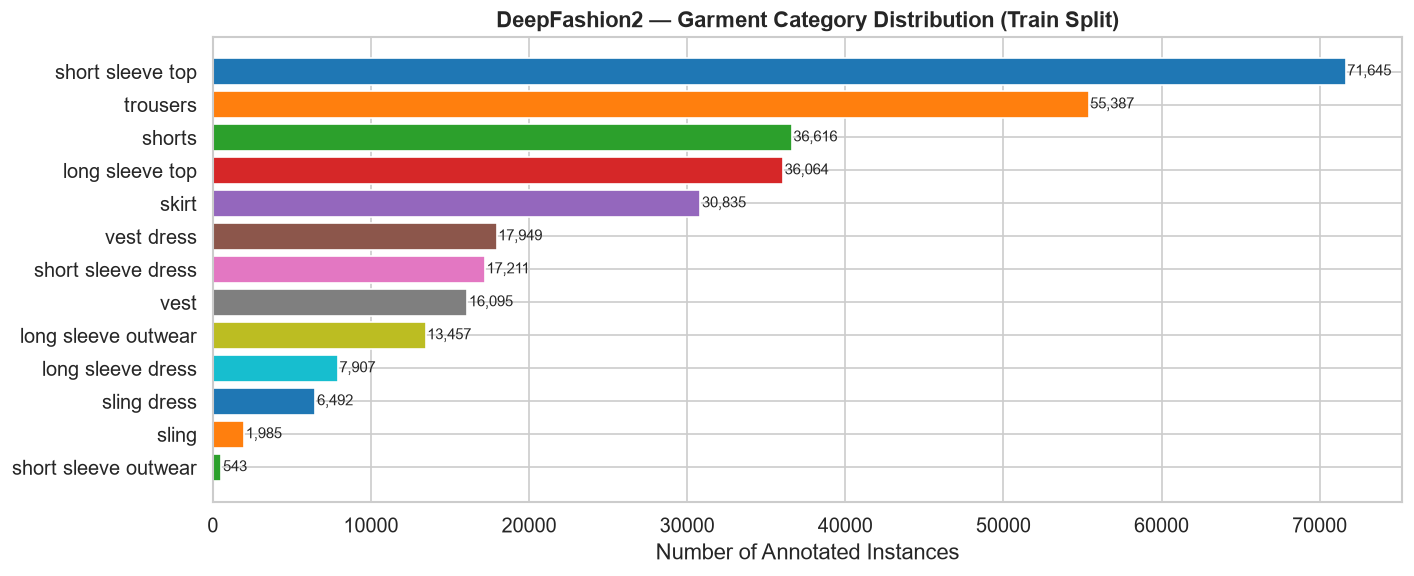

In [11]:
# ── Category distribution ─────────────────────────────────────────────────────
cat_counts = (
    df.groupby(['category_id', 'category_name'])
      .size()
      .reset_index(name='count')
      .sort_values('count', ascending=False)
)
cat_counts['pct'] = (cat_counts['count'] / cat_counts['count'].sum() * 100).round(2)

print('📊 Garment Category Distribution (Training Split):')
print(cat_counts.to_string(index=False))

plt.figure(figsize=(12, 5))
palette = sns.color_palette('tab10', n_colors=len(cat_counts))
bars = plt.barh(cat_counts['category_name'], cat_counts['count'],
                color=palette, edgecolor='white')
plt.xlabel('Number of Annotated Instances')
plt.title('DeepFashion2 — Garment Category Distribution (Train Split)', fontweight='bold')
for bar, count in zip(bars, cat_counts['count']):
    plt.text(bar.get_width() + 100, bar.get_y() + bar.get_height()/2,
             f'{count:,}', va='center', fontsize=9)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

✅ 312,186 items have valid bounding boxes.
⚠️  0 items are missing bounding boxes.

Bounding Box Statistics (px):
         bbox_w    bbox_h  bbox_area
count  312186.0  312186.0   312186.0
mean      293.7     357.0   117908.5
std       121.8     169.1    94792.2
min         0.0       0.0        0.0
25%       201.0     225.0    48048.0
50%       275.0     330.0    89572.5
75%       378.0     468.0   163450.0
max      1048.0    1319.0  1158082.0


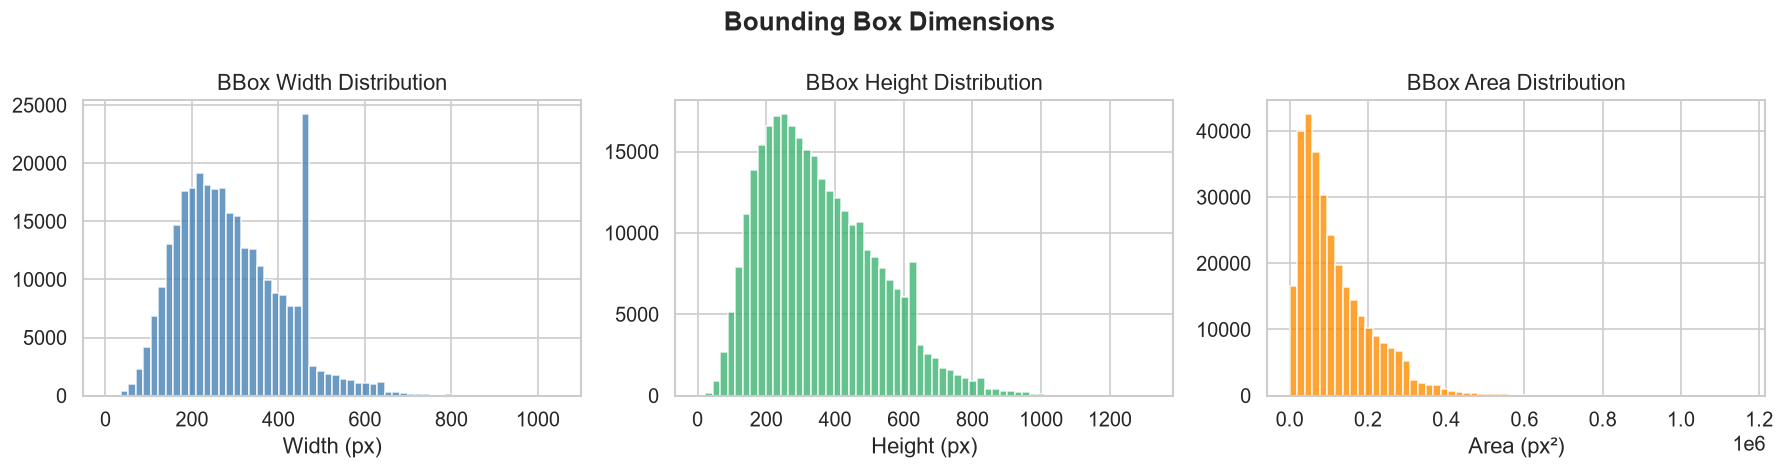

In [12]:
# ── Bounding box analysis ─────────────────────────────────────────────────────
df_bbox = df[df['has_bbox'] == True].copy()

print(f'✅ {len(df_bbox):,} items have valid bounding boxes.')
print(f'⚠️  {len(df) - len(df_bbox):,} items are missing bounding boxes.')
print()
print('Bounding Box Statistics (px):')
print(df_bbox[['bbox_w', 'bbox_h', 'bbox_area']].describe().round(1).to_string())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(df_bbox['bbox_w'].dropna(),   bins=60, color='steelblue',    alpha=0.8, edgecolor='white')
axes[0].set_title('BBox Width Distribution');  axes[0].set_xlabel('Width (px)')
axes[1].hist(df_bbox['bbox_h'].dropna(),   bins=60, color='mediumseagreen', alpha=0.8, edgecolor='white')
axes[1].set_title('BBox Height Distribution'); axes[1].set_xlabel('Height (px)')
axes[2].hist(df_bbox['bbox_area'].dropna(), bins=60, color='darkorange',   alpha=0.8, edgecolor='white')
axes[2].set_title('BBox Area Distribution');   axes[2].set_xlabel('Area (px²)')
plt.suptitle('Bounding Box Dimensions', fontweight='bold')
plt.tight_layout()
plt.show()

Segmentation Coverage:
  Items with segmentation polygons : 312,186  (100.0%)
  Items with landmark annotations  : 312,186  (100.0%)

Avg segmentation polygon points per item:
  38.8  (min=4, max=928)


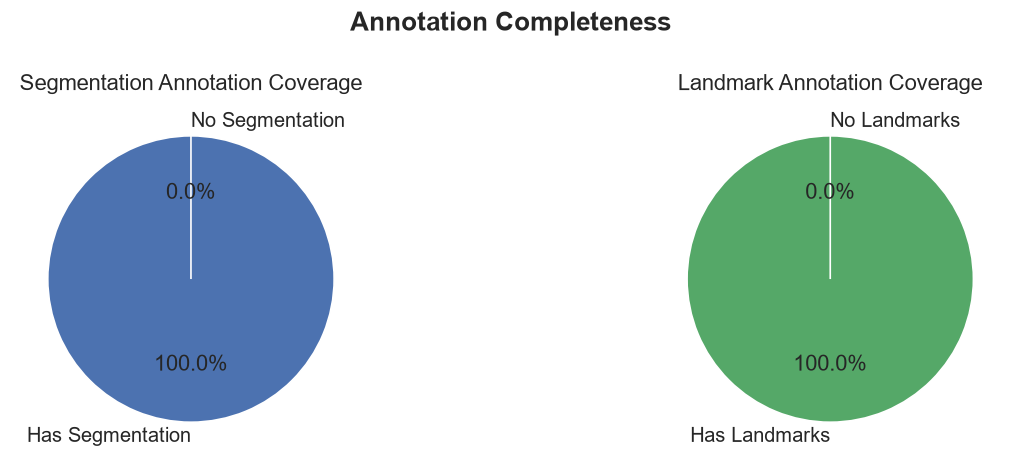

In [13]:
# ── Segmentation & landmark coverage ─────────────────────────────────────────
print('Segmentation Coverage:')
print(f'  Items with segmentation polygons : {df["has_seg"].sum():,}  '
      f'({df["has_seg"].mean()*100:.1f}%)')
print(f'  Items with landmark annotations  : {df["has_landmarks"].sum():,}  '
      f'({df["has_landmarks"].mean()*100:.1f}%)')
print()
print('Avg segmentation polygon points per item:')
print(f'  {df["seg_point_count"].mean():.1f}  (min={df["seg_point_count"].min()}, max={df["seg_point_count"].max()})')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
seg_labels  = ['Has Segmentation', 'No Segmentation']
seg_sizes   = [df['has_seg'].sum(), (~df['has_seg']).sum()]
lm_labels   = ['Has Landmarks', 'No Landmarks']
lm_sizes    = [df['has_landmarks'].sum(), (~df['has_landmarks']).sum()]

axes[0].pie(seg_sizes, labels=seg_labels, autopct='%1.1f%%',
            colors=['#4C72B0', '#DD8452'], startangle=90)
axes[0].set_title('Segmentation Annotation Coverage')
axes[1].pie(lm_sizes, labels=lm_labels, autopct='%1.1f%%',
            colors=['#55A868', '#C44E52'], startangle=90)
axes[1].set_title('Landmark Annotation Coverage')
plt.suptitle('Annotation Completeness', fontweight='bold')
plt.tight_layout()
plt.show()

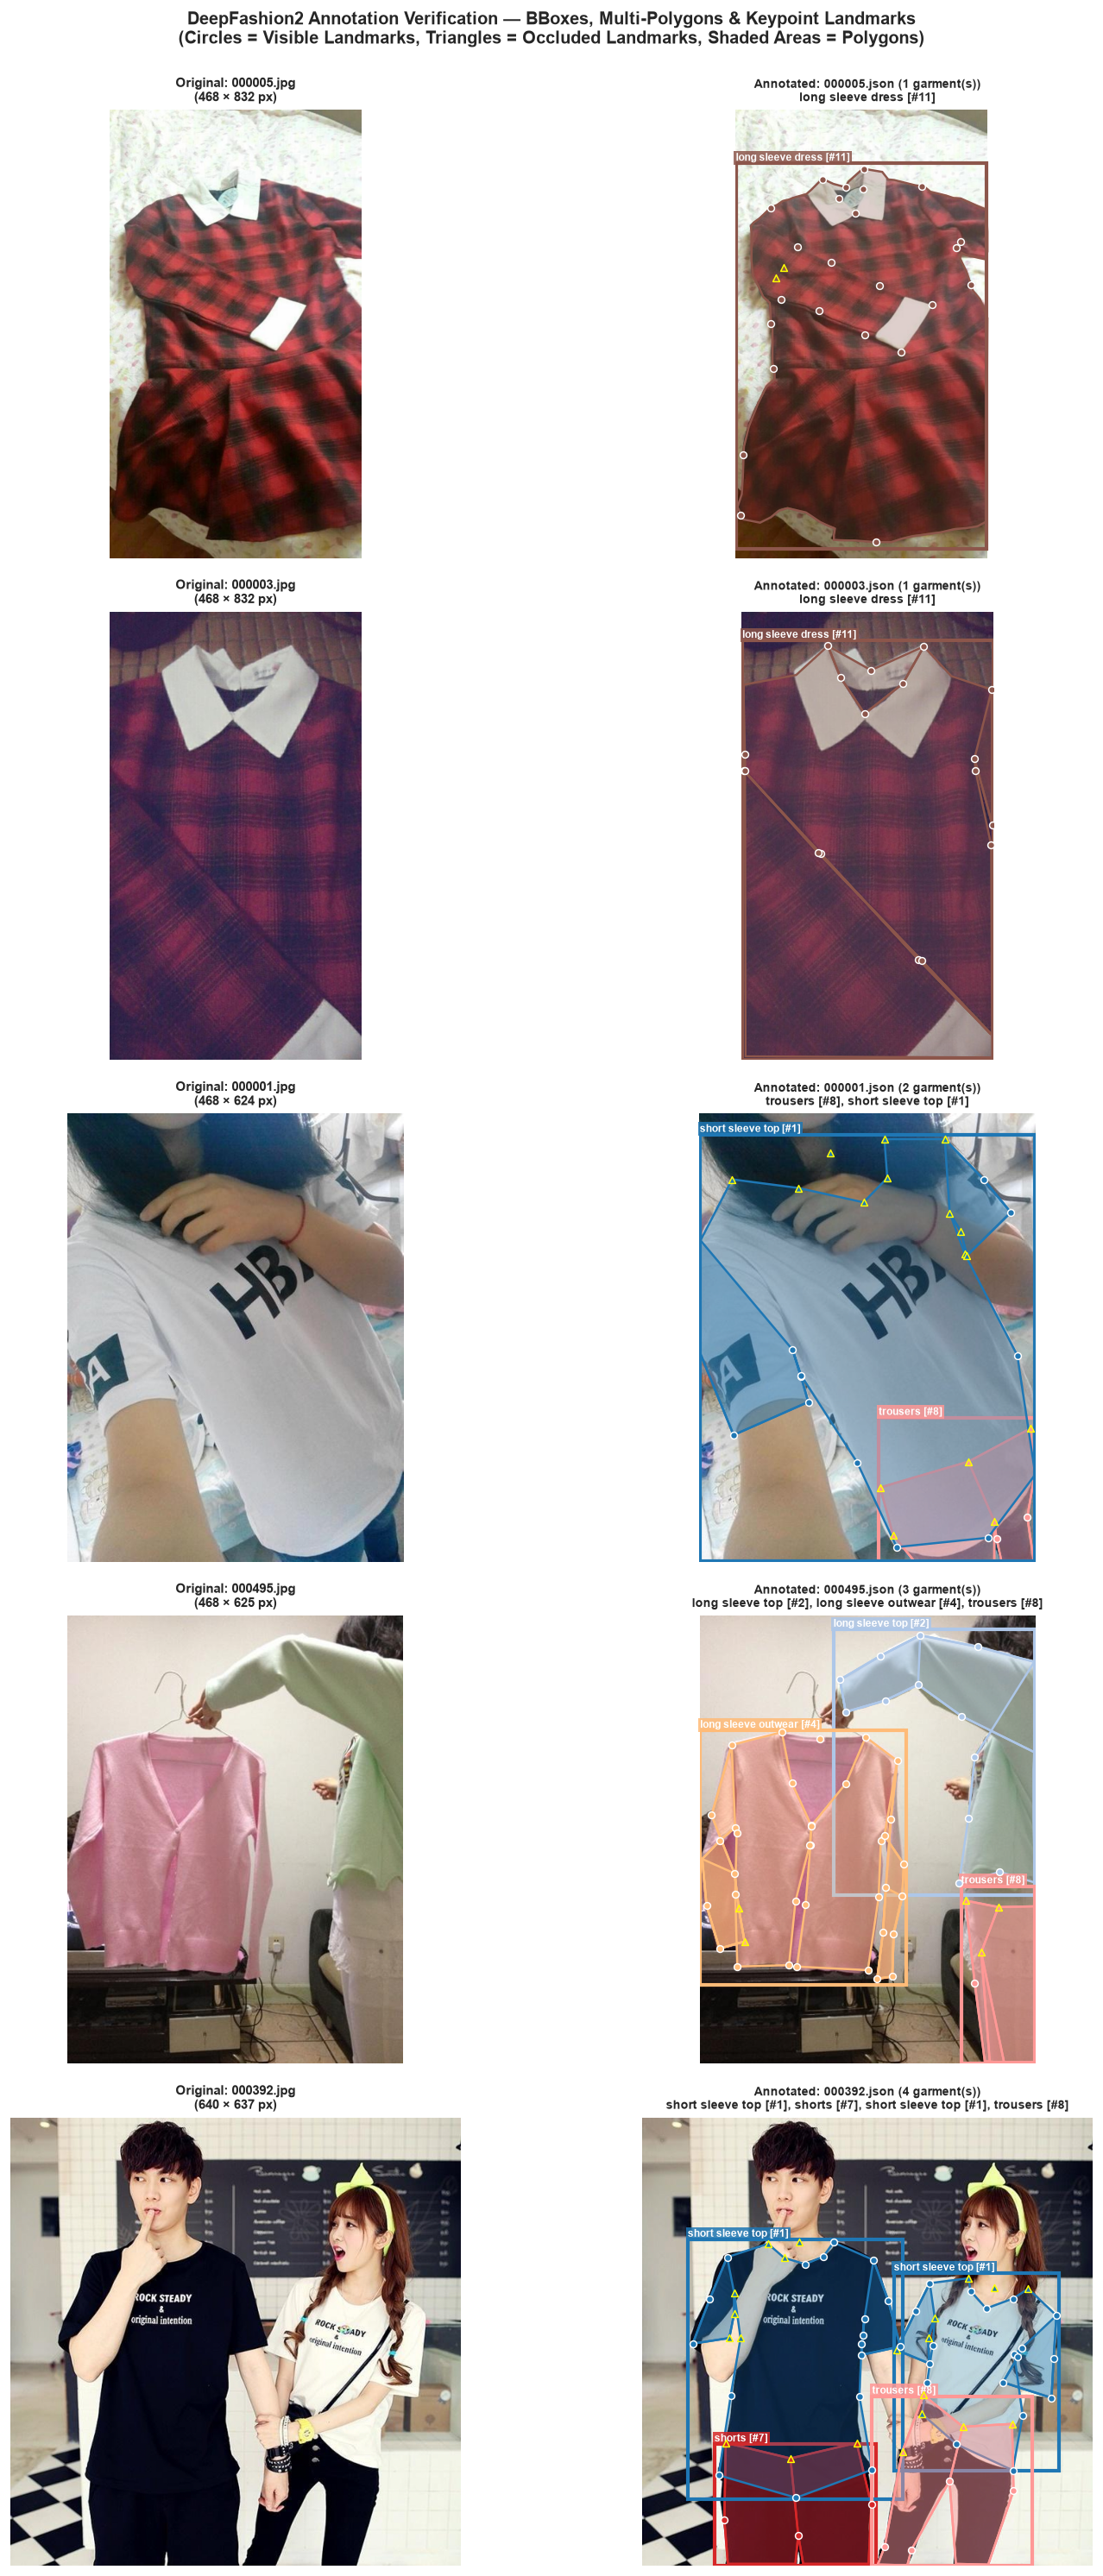

In [9]:
# ── Visualise annotated samples ───────────────────────────────────────────────
#    Display original images alongside ground-truth bounding boxes,
#    multi-polygon segmentation masks, and keypoint landmarks.

CMAP = plt.colormaps['tab20']

def draw_sample_annotations(img_path: Path, anno_path: Path, ax_orig: plt.Axes, ax_anno: plt.Axes) -> None:
    """Overlay bounding boxes, segmentation polygons, and landmarks on an image."""
    try:
        img = Image.open(img_path).convert('RGB')
        w, h = img.size
    except Exception as e:
        ax_orig.text(0.5, 0.5, f'Image load failed\n{e}', ha='center', va='center')
        ax_anno.text(0.5, 0.5, f'Image load failed\n{e}', ha='center', va='center')
        ax_orig.axis('off')
        ax_anno.axis('off')
        return

    # Original image
    ax_orig.imshow(img)
    ax_orig.set_title(f'Original: {img_path.name}\n({w} × {h} px)', fontsize=9, fontweight='bold')
    ax_orig.axis('off')

    # Annotated image
    ax_anno.imshow(img)
    if not (anno_path and anno_path.exists()):
        ax_anno.text(0.5, 0.5, 'Annotation not found', ha='center', va='center')
        ax_anno.axis('off')
        return

    parsed = parse_annotation(anno_path)
    garment_labels = []

    for idx, item in enumerate(parsed['items']):
        cat_id = item.get('category_id', 0)
        cat_nm = CATEGORY_MAP.get(cat_id, item.get('category_name', f'Cat {cat_id}'))
        garment_labels.append(f'{cat_nm} [#{cat_id}]')
        color = CMAP((cat_id - 1) % 20)

        # 1. Bounding box [x1, y1, x2, y2]
        bbox = item.get('bounding_box', [])
        if len(bbox) == 4:
            x1, y1, x2, y2 = bbox
            x1_c = max(0.0, min(float(x1), float(w)))
            y1_c = max(0.0, min(float(y1), float(h)))
            x2_c = max(0.0, min(float(x2), float(w)))
            y2_c = max(0.0, min(float(y2), float(h)))
            bw = x2_c - x1_c
            bh = y2_c - y1_c
            if bw > 0 and bh > 0:
                rect = patches.Rectangle(
                    (x1_c, y1_c), bw, bh,
                    linewidth=2.5, edgecolor=color, facecolor='none'
                )
                ax_anno.add_patch(rect)
                ax_anno.text(
                    x1_c, max(0.0, y1_c - 4),
                    f'{cat_nm} [#{cat_id}]',
                    color='white', fontsize=7, fontweight='bold',
                    bbox=dict(boxstyle='square,pad=0.2', fc=color, ec='none', alpha=0.85)
                )
        else:
            print(f'⚠️  Invalid bounding box in {anno_path.name} item {idx+1}: {bbox}')

        # 2. Segmentation polygons (list of coordinate lists)
        seg = item.get('segmentation', [])
        for p_idx, poly_coords in enumerate(seg):
            if isinstance(poly_coords, (list, tuple, np.ndarray)) and len(poly_coords) >= 6:
                poly_arr = np.array(poly_coords, dtype=float).reshape(-1, 2)
                poly = patches.Polygon(
                    poly_arr, closed=True, fill=True,
                    facecolor=(*color[:3], 0.28),
                    edgecolor=color, linewidth=1.5
                )
                ax_anno.add_patch(poly)
            else:
                print(f'⚠️  Polygon {p_idx} in {anno_path.name} has invalid coords: {poly_coords}')

        # 3. Keypoint landmarks [x, y, v, x, y, v, ...]
        lms = item.get('landmarks', [])
        if isinstance(lms, (list, tuple, np.ndarray)) and len(lms) >= 3:
            if len(lms) % 3 != 0:
                print(f'⚠️  Landmarks length {len(lms)} not divisible by 3 in {anno_path.name}')
            else:
                lms_arr = np.array(lms, dtype=float).reshape(-1, 3)
                vis_mask = (lms_arr[:, 2] == 2)
                occ_mask = (lms_arr[:, 2] == 1)
                if np.any(vis_mask):
                    ax_anno.scatter(
                        lms_arr[vis_mask, 0], lms_arr[vis_mask, 1],
                        s=22, c=[color], edgecolors='white', linewidths=0.9,
                        marker='o', zorder=5
                    )
                if np.any(occ_mask):
                    ax_anno.scatter(
                        lms_arr[occ_mask, 0], lms_arr[occ_mask, 1],
                        s=22, c=[color], edgecolors='yellow', linewidths=0.9,
                        marker='^', zorder=5
                    )

    ax_anno.set_title(
        f"Annotated: {anno_path.name} ({len(parsed['items'])} garment(s))\n{', '.join(garment_labels)}",
        fontsize=8.5, fontweight='bold'
    )
    ax_anno.axis('off')

# ── Render verified representative samples ──────────────────────────────────
# 1. 000005: Single garment, clean polygon
# 2. 000003: Single garment, 5 disconnected polygon regions
# 3. 000001: Two garments (paired outfit: top + trousers)
# 4. 000495: Three garments (layered ensemble: top + outerwear + trousers)
# 5. 000392: Four garments in multi-person scene
SAMPLE_STEMS = ['000005', '000003', '000001', '000495', '000392']

img_dir = (splits_found.get('train', {}).get('img_dir') if 'splits_found' in dir() else None) or TRAIN_IMAGE_DIR
anno_dir = (splits_found.get('train', {}).get('anno_dir') if 'splits_found' in dir() else None) or TRAIN_ANNOTATION_DIR

fig, axes = plt.subplots(len(SAMPLE_STEMS), 2, figsize=(14, 25), dpi=120)

for i, stem in enumerate(SAMPLE_STEMS):
    img_path  = img_dir / f'{stem}.jpg'
    anno_path = anno_dir / f'{stem}.json'
    draw_sample_annotations(img_path, anno_path, axes[i, 0], axes[i, 1])

plt.suptitle(
    'DeepFashion2 Annotation Verification — BBoxes, Multi-Polygons & Keypoint Landmarks\n'
    '(Circles = Visible Landmarks, Triangles = Occluded Landmarks, Shaded Areas = Polygons)',
    fontsize=12, fontweight='bold', y=0.995
)
plt.tight_layout()
plt.show()


---
## Stage 4 — Image Quality Analysis

We analyse image dimensions, aspect ratios, file sizes, blur, brightness and contrast.  
Corrupted images are flagged but **never deleted automatically**.

In [14]:
def compute_blur_score(img_array: np.ndarray) -> float:
    """
    Laplacian variance — higher = sharper.
    Values below ~100 are typically blurry.
    """
    gray = cv2.cvtColor(img_array, cv2.COLOR_RGB2GRAY)
    return float(cv2.Laplacian(gray, cv2.CV_64F).var())


def compute_brightness_contrast(img_array: np.ndarray):
    """Mean brightness and std-dev (contrast proxy) on grayscale."""
    gray = cv2.cvtColor(img_array, cv2.COLOR_RGB2GRAY)
    return float(gray.mean()), float(gray.std())


# ── Sample up to 3,000 images for quality analysis (full scan can be slow) ───
MAX_QUALITY_SAMPLE = 3000
SCAN_SPLIT = 'train' if 'SCAN_SPLIT' not in dir() else SCAN_SPLIT
img_paths_all = inventory[SCAN_SPLIT]['image_paths']
random.seed(42)
sample_img_paths = random.sample(
    img_paths_all, min(MAX_QUALITY_SAMPLE, len(img_paths_all))
)

print(f'🔎 Analysing {len(sample_img_paths):,} sampled images for quality metrics...')
print('   (Subsample used for speed; full scan can be run by setting MAX_QUALITY_SAMPLE to a larger value)')

quality_records = []
corrupted_files = []

for img_path in tqdm(sample_img_paths, desc='Quality scan'):
    try:
        with Image.open(img_path) as pil_img:
            w, h    = pil_img.size
            fmt     = pil_img.format
            mode    = pil_img.mode
            # Force full decode to catch corrupt JPEGs
            pil_img.verify()

        # Re-open after verify (verify closes the file)
        with Image.open(img_path) as pil_img:
            img_arr = np.array(pil_img.convert('RGB'))

        blur       = compute_blur_score(img_arr)
        brightness, contrast = compute_brightness_contrast(img_arr)
        file_size  = img_path.stat().st_size
        aspect     = round(w / h, 3)

        quality_records.append({
            'file'       : img_path.stem,
            'width'      : w,
            'height'     : h,
            'aspect'     : aspect,
            'megapixels' : round(w * h / 1e6, 3),
            'file_size_kb': round(file_size / 1024, 1),
            'blur_score' : round(blur, 2),
            'brightness' : round(brightness, 2),
            'contrast'   : round(contrast, 2),
            'mode'       : mode,
            'format'     : fmt,
        })
    except Exception as e:
        corrupted_files.append({'file': str(img_path), 'error': str(e)})

df_quality = pd.DataFrame(quality_records)
print(f'\n✅ Quality scan complete.')
print(f'   Valid images   : {len(df_quality):,}')
print(f'   Corrupted / unreadable : {len(corrupted_files):,}')
if corrupted_files:
    print('\n⚠️  Corrupted files (first 10):')
    for c in corrupted_files[:10]:
        print(f'   {c["file"]}  →  {c["error"]}')


🔎 Analysing 3,000 sampled images for quality metrics...
   (Subsample used for speed; full scan can be run by setting MAX_QUALITY_SAMPLE to a larger value)

✅ Quality scan complete.
   Valid images   : 3,000
   Corrupted / unreadable : 0


In [15]:
print('Image Quality Statistics:')
print(df_quality[['width', 'height', 'megapixels', 'file_size_kb',
                   'blur_score', 'brightness', 'contrast', 'aspect']]
      .describe().round(2).to_string())

# ── Blurry image threshold ────────────────────────────────────────────────────
BLUR_THRESHOLD = 100.0
blurry = df_quality[df_quality['blur_score'] < BLUR_THRESHOLD]
print(f'\n📌 Blurry images (blur_score < {BLUR_THRESHOLD}): '
      f'{len(blurry):,}  ({len(blurry)/len(df_quality)*100:.1f}%)')

Image Quality Statistics:
         width   height  megapixels  file_size_kb  blur_score  brightness  contrast   aspect
count  3000.00  3000.00     3000.00       3000.00     3000.00     3000.00   3000.00  3000.00
mean    609.40   765.85        0.48         54.34      630.24      148.34     62.87     0.83
std     152.88   217.00        0.23         26.90      708.43       37.85     14.49     0.25
min     100.00   100.00        0.01          2.80        6.52       10.91     11.21     0.34
25%     468.00   624.00        0.29         34.68      212.69      119.86     53.05     0.67
50%     640.00   702.00        0.41         47.90      419.66      148.10     63.46     0.75
75%     750.00   960.00        0.61         68.15      790.84      176.40     72.78     0.95
max     880.00  1500.00        1.27        207.30     8241.76      242.67    104.92     1.89

📌 Blurry images (blur_score < 100.0): 271  (9.0%)


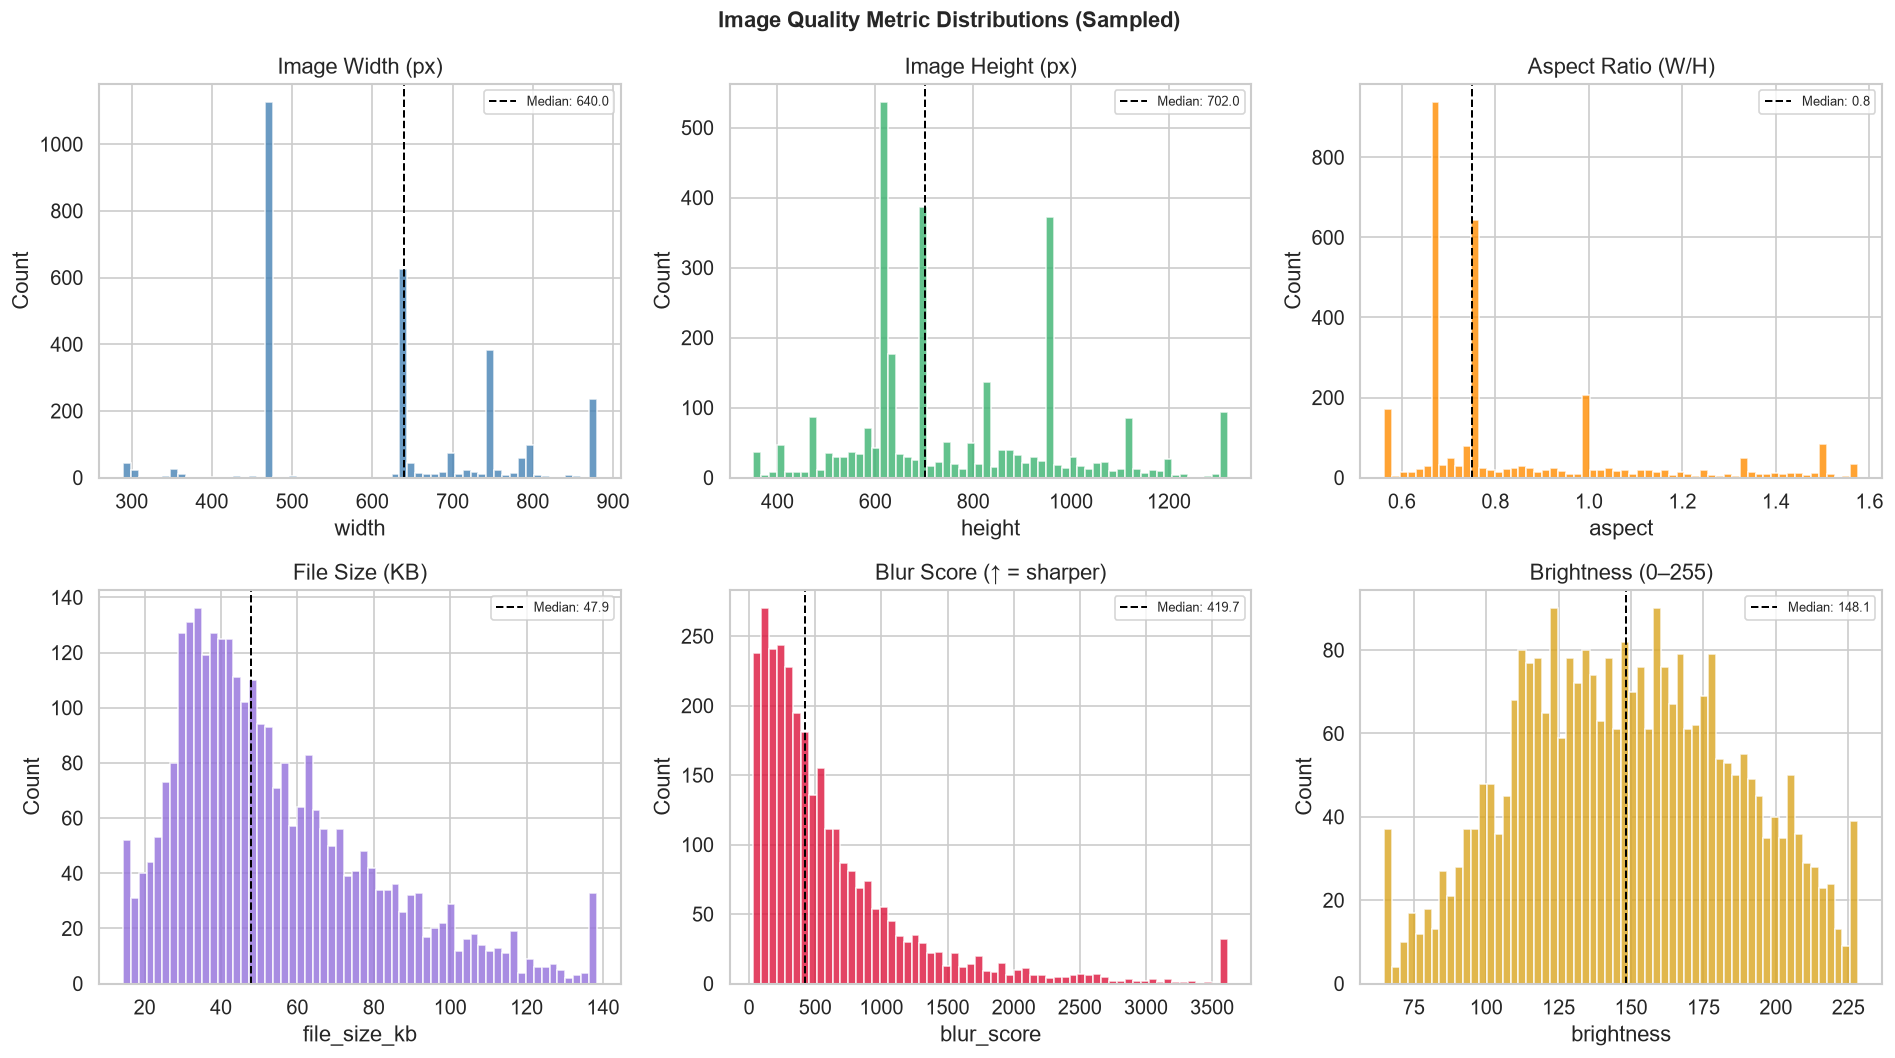

In [16]:
# ── Quality distributions ─────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

metrics = [
    ('width',         'Image Width (px)',         'steelblue'),
    ('height',        'Image Height (px)',        'mediumseagreen'),
    ('aspect',        'Aspect Ratio (W/H)',       'darkorange'),
    ('file_size_kb',  'File Size (KB)',           'mediumpurple'),
    ('blur_score',    'Blur Score (↑ = sharper)', 'crimson'),
    ('brightness',    'Brightness (0–255)',       'goldenrod'),
]

for ax, (col, title, color) in zip(axes.flat, metrics):
    data = df_quality[col].dropna()
    # Clip extreme outliers for readability
    p1, p99 = data.quantile(0.01), data.quantile(0.99)
    ax.hist(data.clip(p1, p99), bins=60, color=color, alpha=0.8, edgecolor='white')
    ax.set_title(title)
    ax.set_xlabel(col)
    ax.set_ylabel('Count')
    ax.axvline(data.median(), color='black', linestyle='--', linewidth=1.2,
               label=f'Median: {data.median():.1f}')
    ax.legend(fontsize=8)

plt.suptitle('Image Quality Metric Distributions (Sampled)', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.show()

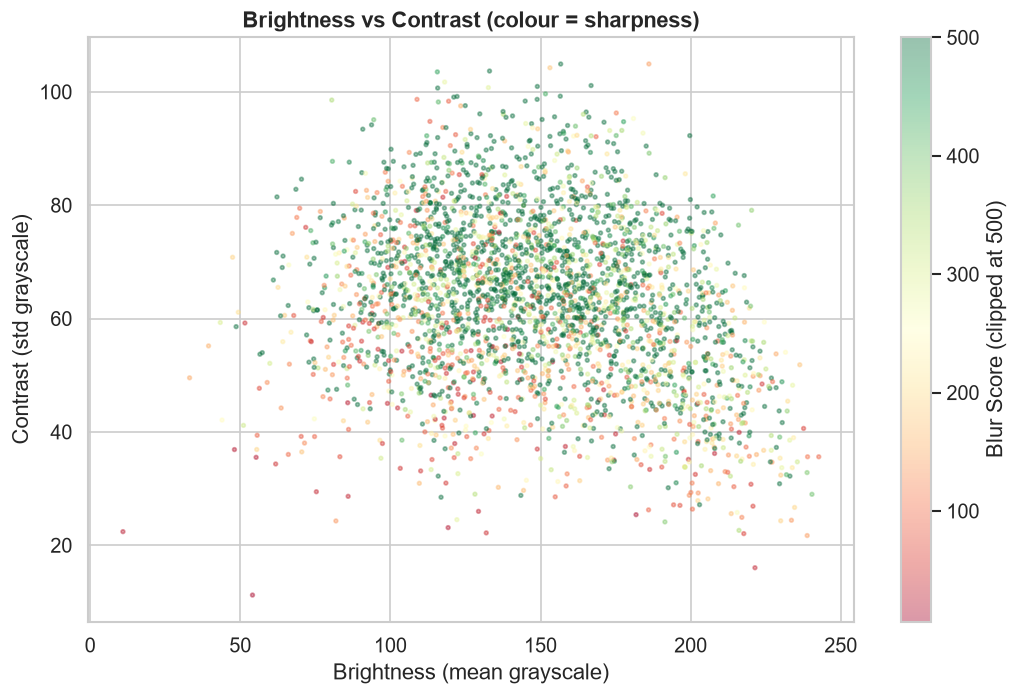

In [17]:
# ── Scatter: Brightness vs Contrast, coloured by blur score ──────────────────
plt.figure(figsize=(9, 6))
sc = plt.scatter(
    df_quality['brightness'], df_quality['contrast'],
    c=df_quality['blur_score'].clip(0, 500),
    cmap='RdYlGn', alpha=0.4, s=5
)
plt.colorbar(sc, label='Blur Score (clipped at 500)')
plt.xlabel('Brightness (mean grayscale)')
plt.ylabel('Contrast (std grayscale)')
plt.title('Brightness vs Contrast (colour = sharpness)', fontweight='bold')
plt.tight_layout()
plt.show()

---
## Stage 5 — Dataset Diversity

Measure class imbalance, viewpoint variety, occlusion levels, multi-garment complexity and image source diversity.

In [18]:
# ── Viewpoint distribution ────────────────────────────────────────────────────
# DeepFashion2 viewpoint codes (CVPR 2019):
#   1 = No Wear (flat-lay, ghost mannequin, clothes on hanger)
#   2 = Frontal (worn on person/model, front-facing view)
#   3 = Side/Back (worn on person/model, profile or rear view)
VIEWPOINT_MAP = {
    1: 'No Wear',
    2: 'Frontal',
    3: 'Side/Back'
}

viewpoint_counts = df['viewpoint'].value_counts().sort_index()
print('👁️  Viewpoint Distribution:')
for vp, cnt in viewpoint_counts.items():
    print(f'   [{vp}] {VIEWPOINT_MAP.get(vp, str(vp)):12s}: {cnt:>8,}  ({cnt/len(df)*100:.1f}%)')
print(f'   Total: {viewpoint_counts.sum():,}')


👁️  Viewpoint Distribution:
   [1] No Wear     :   22,675  (7.3%)
   [2] Frontal     :  244,459  (78.3%)
   [3] Side/Back   :   45,052  (14.4%)
   Total: 312,186


In [19]:
# ── Occlusion distribution ────────────────────────────────────────────────────
# DeepFashion2 occlusion levels (defined in CVPR 2019 paper based on landmark occlusion):
#   1 = Slight / Partial (fewer than 20% of garment landmarks occluded)
#   2 = Medium (between 20% and 50% of garment landmarks occluded)
#   3 = Heavy (more than 50% of garment landmarks occluded)
# Note: The annotation JSON stores discrete integers 1, 2, 3.
OCCLUSION_MAP = {1: 'Slight', 2: 'Medium', 3: 'Heavy'}

occ_counts = df['occlusion'].value_counts().sort_index()
print('🕶️  Occlusion Level Distribution:')
for occ, cnt in occ_counts.items():
    label = OCCLUSION_MAP.get(occ, str(occ))
    bar   = '█' * int(cnt / occ_counts.max() * 30)
    print(f'   [{occ}] {label:8s}: {cnt:>8,}  ({cnt/len(df)*100:.1f}%)  {bar}')


🕶️  Occlusion Level Distribution:
   [1] Slight  :  145,379  (46.6%)  █████████████████████████████
   [2] Medium  :  147,102  (47.1%)  ██████████████████████████████
   [3] Heavy   :   19,705  (6.3%)  ████


In [20]:
# ── Zoom / scale diversity ─────────────────────────────────────────────────────
# DeepFashion2 zoom-in levels (CVPR 2019 annotation categories based on landmark truncation):
#   1 = No Zoom
#   2 = Medium Zoom
#   3 = Large Zoom
# Note: Zoom-in indicates garment landmark truncation (landmarks outside image boundaries)
#       as discrete annotation categories without claiming exact numeric proportions.
ZOOM_MAP = {
    1: 'No Zoom',
    2: 'Medium Zoom',
    3: 'Large Zoom'
}

# DeepFashion2 scale levels (defined in CVPR 2019: Small, Modest, Large):
#   1 = Small
#   2 = Modest
#   3 = Large
# Note: Discrete semantic scales annotated without arbitrary bounding-box area percentage thresholds.
SCALE_MAP = {
    1: 'Small',
    2: 'Modest',
    3: 'Large'
}

zoom_counts = df['zoom_in'].value_counts().sort_index()
print('🔍  Zoom Diversity (Garment Instances):')
for z, cnt in zoom_counts.items():
    print(f'   [{z}] {ZOOM_MAP.get(z, str(z)):12s}: {cnt:>8,}  ({cnt/len(df)*100:.1f}%)')
print(f'   Total: {zoom_counts.sum():,}\n')

# Check / populate 'scale' column in df
if 'scale' not in df.columns:
    audit_file = PROJ_ROOT / 'wardrobe_ml' / 'outputs' / 'metadata_audit_report.json' if 'PROJ_ROOT' in dir() else Path('../outputs/metadata_audit_report.json')
    if not audit_file.exists():
        audit_file = Path('wardrobe_ml/outputs/metadata_audit_report.json')
    if audit_file.exists():
        with open(audit_file, 'r', encoding='utf-8') as f:
            _meta = json.load(f)
        scale_counts = pd.Series({int(k): v for k, v in _meta['metadata_distributions']['scale'].items()}).sort_index()
    else:
        scale_counts = pd.Series()
else:
    scale_counts = df['scale'].value_counts().sort_index()

print('📏  Scale Diversity (Garment Instances):')
for s, cnt in scale_counts.items():
    print(f'   [{s}] {SCALE_MAP.get(s, str(s)):12s}: {cnt:>8,}  ({cnt/scale_counts.sum()*100:.1f}%)')
print(f'   Total: {scale_counts.sum():,}')


🔍  Zoom Diversity (Garment Instances):
   [1] No Zoom     :  211,894  (67.9%)
   [2] Medium Zoom :   66,643  (21.3%)
   [3] Large Zoom  :   33,649  (10.8%)
   Total: 312,186

📏  Scale Diversity (Garment Instances):
   [1] Small       :   78,735  (25.2%)
   [2] Modest      :  157,021  (50.3%)
   [3] Large       :   76,430  (24.5%)
   Total: 312,186


👕  Items per Image (garment count per photo):
count    191961.00
mean          1.63
std           0.54
min           1.00
25%           1.00
50%           2.00
75%           2.00
max           8.00

   Single-item images   : 76,107
   2-item images        : 112,530
   3+ item images       : 3,324


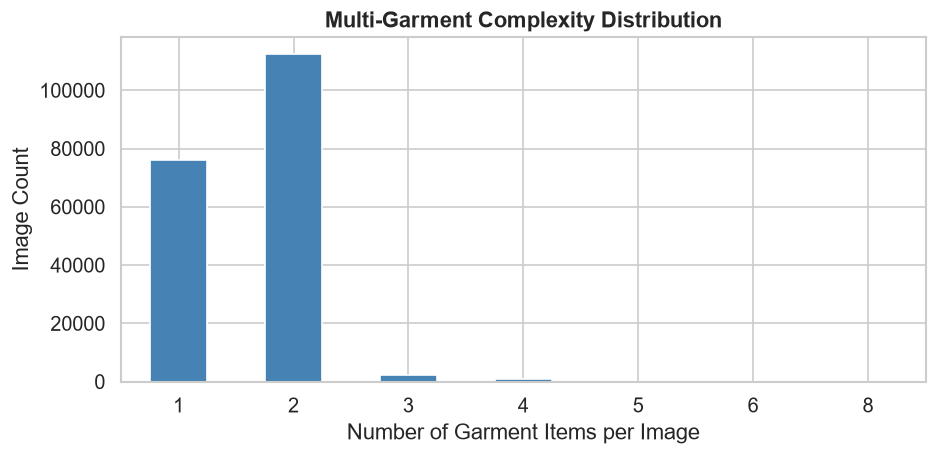

In [21]:
# ── Multi-garment images ───────────────────────────────────────────────────────
items_per_image = df.groupby('file')['category_id'].count()

print('👕  Items per Image (garment count per photo):')
print(items_per_image.describe().round(2).to_string())
print()
print(f'   Single-item images   : {(items_per_image == 1).sum():,}')
print(f'   2-item images        : {(items_per_image == 2).sum():,}')
print(f'   3+ item images       : {(items_per_image >= 3).sum():,}')

plt.figure(figsize=(8, 4))
items_per_image.value_counts().sort_index().plot(kind='bar', color='steelblue', edgecolor='white')
plt.xlabel('Number of Garment Items per Image')
plt.ylabel('Image Count')
plt.title('Multi-Garment Complexity Distribution', fontweight='bold')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

📸  Image Source Distribution (Unique Images: shop vs user):
   shop        :  132,157  (68.85%)
   user        :   59,804  (31.15%)
   Total: 191,961


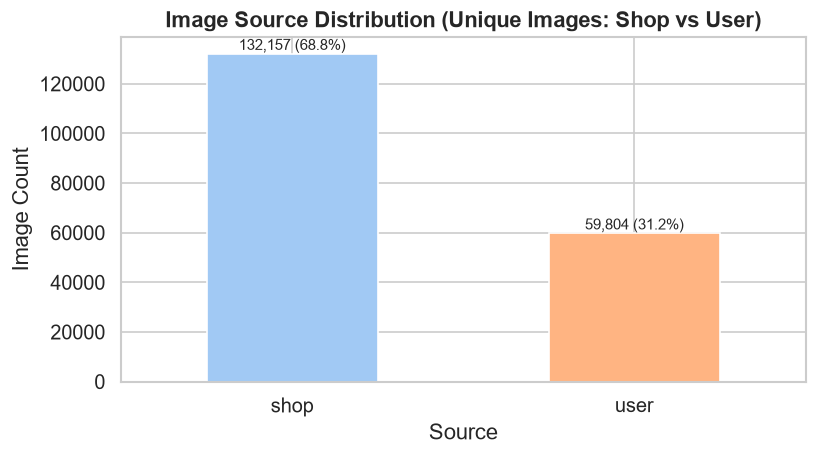

In [22]:
# ── Source / capture diversity ────────────────────────────────────────────────
# DeepFashion2 'source' is image-level metadata: shop vs user
# De-duplicate by image filename to compute image-level distribution
img_source_df = df.drop_duplicates(subset=['file'])
source_counts = img_source_df['source'].value_counts()
n_unique_imgs = len(img_source_df)

print('📸  Image Source Distribution (Unique Images: shop vs user):')
for src, cnt in source_counts.items():
    print(f'   {src:12s}: {cnt:>8,}  ({cnt / n_unique_imgs * 100:.2f}%)')
print(f'   Total: {source_counts.sum():,}')

plt.figure(figsize=(7, 4))
source_counts.plot(kind='bar', color=sns.color_palette('pastel', len(source_counts)), edgecolor='white')
plt.title('Image Source Distribution (Unique Images: Shop vs User)', fontweight='bold')
plt.ylabel('Image Count')
plt.xlabel('Source')
for idx, cnt in enumerate(source_counts):
    plt.text(idx, cnt + 1500, f'{cnt:,} ({cnt/n_unique_imgs*100:.1f}%)', ha='center', fontsize=9)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


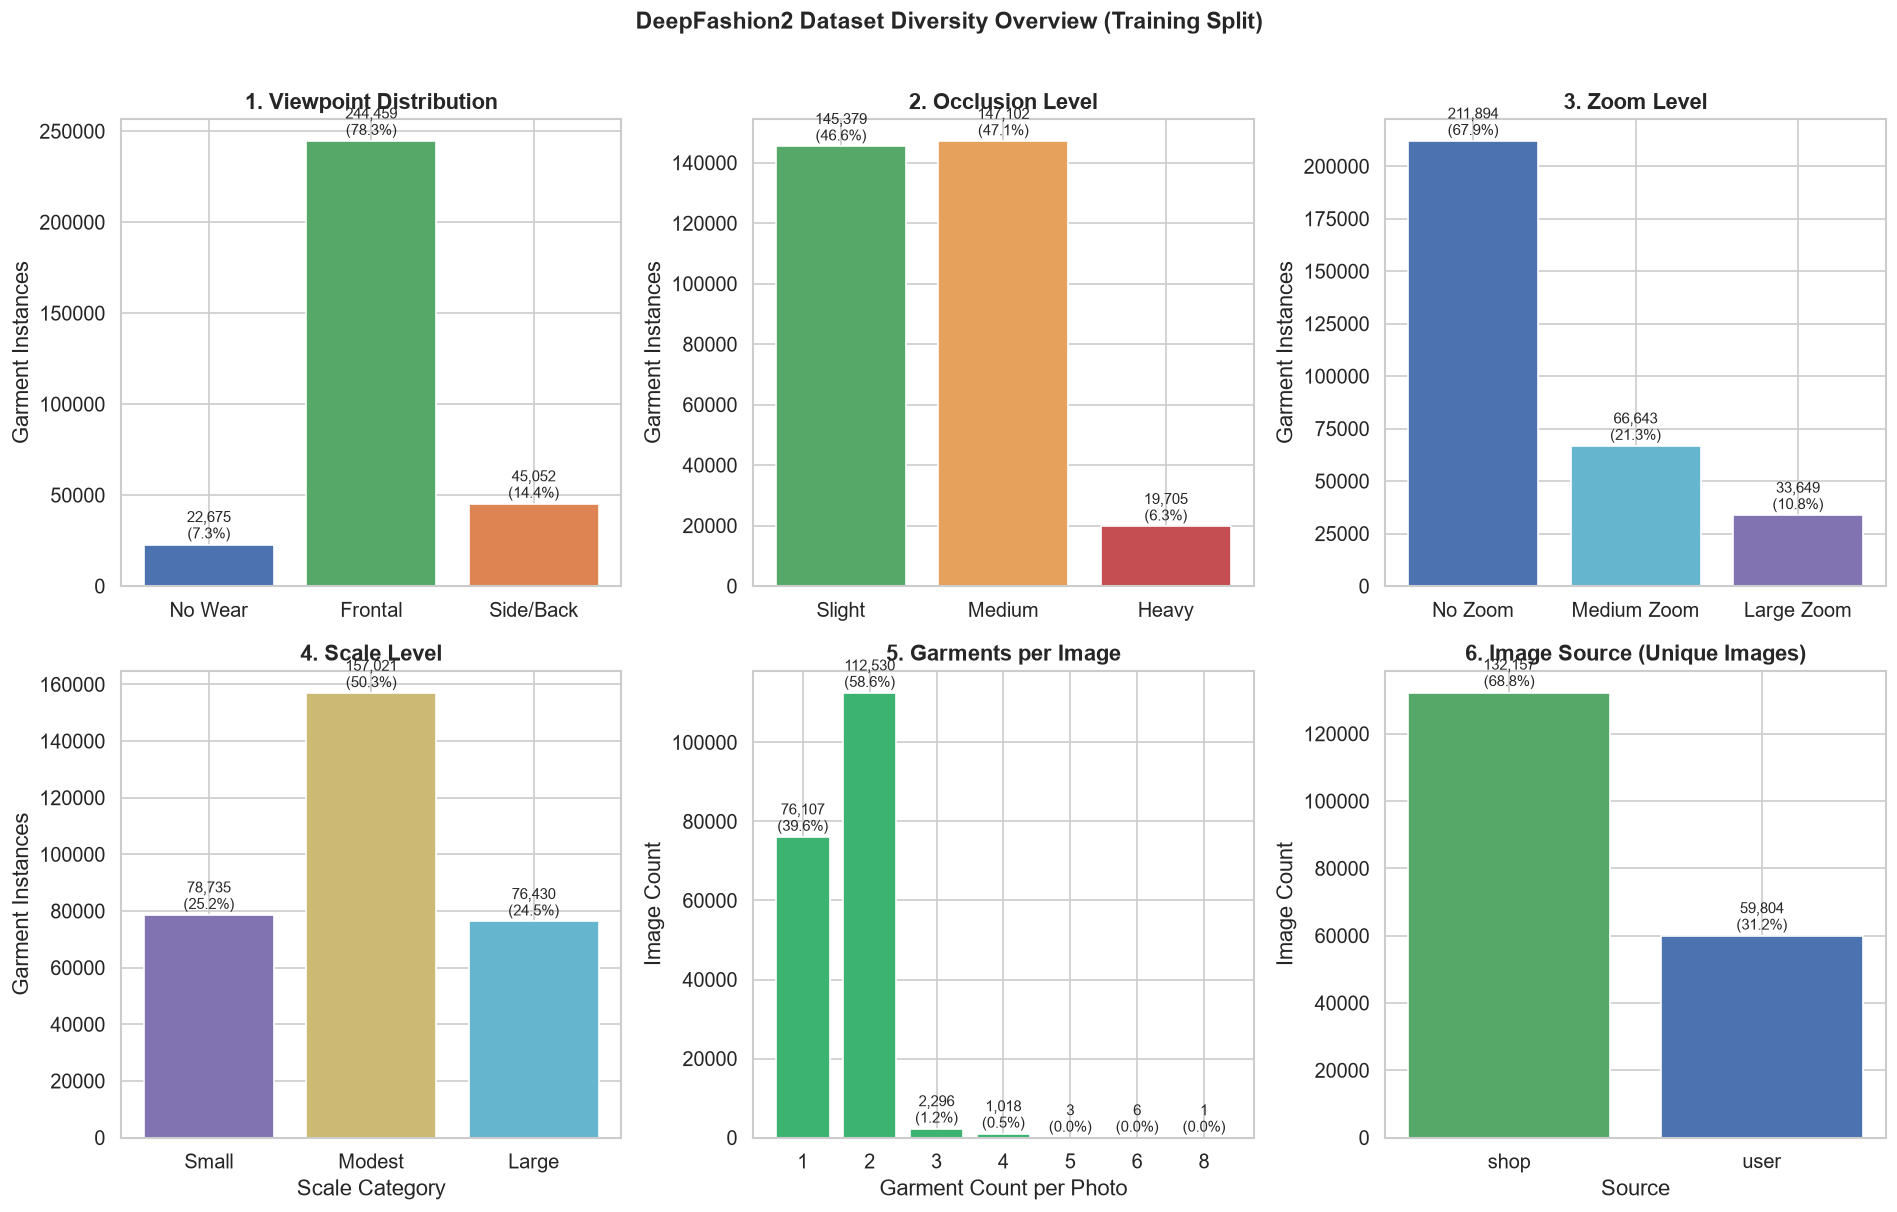

In [23]:
# ── Diversity overview grid ───────────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

# 1. Viewpoint (3 categories)
vp_labels = [VIEWPOINT_MAP.get(k, str(k)) for k in viewpoint_counts.index]
vp_colors = ['#4C72B0', '#55A868', '#DD8452']
axes[0, 0].bar(vp_labels, viewpoint_counts.values, color=vp_colors, edgecolor='white')
axes[0, 0].set_title('1. Viewpoint Distribution', fontweight='bold')
axes[0, 0].set_ylabel('Garment Instances')
for idx, val in enumerate(viewpoint_counts.values):
    axes[0, 0].text(idx, val + 3500, f'{val:,}\n({val/len(df)*100:.1f}%)', ha='center', fontsize=9)

# 2. Occlusion (3 categories)
occ_labels = [OCCLUSION_MAP.get(k, str(k)) for k in occ_counts.index]
occ_colors = ['#55A868', '#E6A15C', '#C44E52']
axes[0, 1].bar(occ_labels, occ_counts.values, color=occ_colors, edgecolor='white')
axes[0, 1].set_title('2. Occlusion Level', fontweight='bold')
axes[0, 1].set_ylabel('Garment Instances')
for idx, val in enumerate(occ_counts.values):
    axes[0, 1].text(idx, val + 2000, f'{val:,}\n({val/len(df)*100:.1f}%)', ha='center', fontsize=9)

# 3. Zoom (3 categories)
zoom_labels = [ZOOM_MAP.get(k, str(k)) for k in zoom_counts.index]
zoom_colors = ['#4C72B0', '#64B5CD', '#8172B2']
axes[0, 2].bar(zoom_labels, zoom_counts.values, color=zoom_colors, edgecolor='white')
axes[0, 2].set_title('3. Zoom Level', fontweight='bold')
axes[0, 2].set_ylabel('Garment Instances')
for idx, val in enumerate(zoom_counts.values):
    axes[0, 2].text(idx, val + 3000, f'{val:,}\n({val/len(df)*100:.1f}%)', ha='center', fontsize=9)

# 4. Scale (3 categories: Small, Modest, Large)
scale_labels = [SCALE_MAP.get(k, str(k)) for k in scale_counts.index]
scale_colors = ['#8172B2', '#CCB974', '#64B5CD']
axes[1, 0].bar(scale_labels, scale_counts.values, color=scale_colors, edgecolor='white')
axes[1, 0].set_title('4. Scale Level', fontweight='bold')
axes[1, 0].set_ylabel('Garment Instances')
axes[1, 0].set_xlabel('Scale Category')
for idx, val in enumerate(scale_counts.values):
    axes[1, 0].text(idx, val + 2000, f'{val:,}\n({val/scale_counts.sum()*100:.1f}%)', ha='center', fontsize=9)

# 5. Garments per image
ipf = items_per_image.value_counts().sort_index()
axes[1, 1].bar(ipf.index.astype(str), ipf.values, color='mediumseagreen', edgecolor='white')
axes[1, 1].set_title('5. Garments per Image', fontweight='bold')
axes[1, 1].set_ylabel('Image Count')
axes[1, 1].set_xlabel('Garment Count per Photo')
for idx, (cnt_k, val) in enumerate(ipf.items()):
    axes[1, 1].text(idx, val + 1500, f'{val:,}\n({val/len(items_per_image)*100:.1f}%)', ha='center', fontsize=9)

# 6. Source (Shop vs User unique images)
src_colors = ['#55A868', '#4C72B0']
axes[1, 2].bar(source_counts.index, source_counts.values, color=src_colors, edgecolor='white')
axes[1, 2].set_title('6. Image Source (Unique Images)', fontweight='bold')
axes[1, 2].set_ylabel('Image Count')
axes[1, 2].set_xlabel('Source')
for idx, val in enumerate(source_counts.values):
    axes[1, 2].text(idx, val + 2000, f'{val:,}\n({val/len(img_source_df)*100:.1f}%)', ha='center', fontsize=9)

plt.suptitle('DeepFashion2 Dataset Diversity Overview (Training Split)', fontweight='bold', fontsize=14, y=1.01)
plt.tight_layout()

# Save artifact
out_fig_path = Path(r'C:\Users\Lenovo\Downloads\Fitloop\wardrobe_ml\outputs\cell_28_diversity_overview.png')
plt.savefig(out_fig_path, dpi=150, bbox_inches='tight')

plt.show()


---
## Stage 6 — Dataset Selection & Training Pool Architecture

### 1. Two-Tier Training Architecture
Rather than discarding data or creating an arbitrary fixed-size subset, FitLoop adopts a principled **two-tier architecture**:

1. **Full Production Training Pool (Primary Baseline)**:
   - **191,961 training images** containing **312,186 garment instances** across **14,555 pair clusters**.
   - The full official DeepFashion2 training set remains **100% untouched and preserved** for full-scale production model training and benchmark parity.
   - Zero dataset files are moved, copied, renamed, or deleted.

2. **Optional Pair-Grouped Fast Development Manifest (Secondary Tier)**:
   - For rapid hyperparameter tuning, model prototyping, and CI/CD smoke testing, a pair-grouped development manifest can be generated.
   - Any selection is implemented strictly as a **zero-copy index/manifest (CSV/JSON)** referencing original files.
   - **Cluster-Aware Selection**: Whole `pair_id` clusters are selected intact to preserve cross-camera and shop-to-consumer relationships.
   - **Atomic Images**: All garment instances co-occurring in a single image strictly remain together.

### 2. Multi-Label & Pair Cluster Constraints
DeepFashion2 images exhibit strong multi-label characteristics ($59.9\%$ contain $\ge 2$ garment items, e.g., tops + trousers/skirts). Furthermore, consumer and commercial shop photos of the exact same clothing items share identical `pair_id` identifiers. 

Therefore:
- Evaluation and subsetting must operate at the **pair-cluster level** ($14,555$ clusters) to prevent severe data leakage across shop and user photos.
- Category statistics must distinguish **garment instance counts**, **unique image presence**, and **pair cluster representation**, without double-counting unique totals.


In [24]:
# ── Multi-label and Pair-Cluster Analysis for Training Dataset ───────────────
# Ensure pair_id is populated in df
if 'pair_id' not in df.columns:
    _pair_map_path = Path(r'C:\Users\Lenovo\.gemini\antigravity\brain\57b5c7be-d326-40ec-a129-e53bc9ecb41d\scratch\file_to_pair.json')
    if not _pair_map_path.exists():
        _pair_map_path = OUTPUT_DIR.parent / 'scratch' / 'file_to_pair.json'
    if _pair_map_path.exists():
        with open(_pair_map_path, 'r', encoding='utf-8') as _f:
            _file_to_pair = json.load(_f)
        df['pair_id'] = df['file'].astype(str).map(_file_to_pair)
    else:
        _f2p = {}
        for _p in inventory['train']['anno_paths']:
            try:
                with open(_p, 'r', encoding='utf-8') as _f:
                    _f2p[_p.stem] = json.load(_f).get('pair_id')
            except Exception:
                continue
        df['pair_id'] = df['file'].astype(str).map(_f2p)

total_unique_images = df['file'].nunique()
total_unique_pairs  = df['pair_id'].nunique()
total_garments      = len(df)

# Images per pair distribution
imgs_per_pair = df.groupby('pair_id')['file'].nunique()

print('📊 TRAINING DATASET POOL METRICS:')
print(f'   • Total Garment Instances   : {total_garments:,}')
print(f'   • Total Unique Images       : {total_unique_images:,}')
print(f'   • Total Unique Pair Clusters: {total_unique_pairs:,}')
print(f'   • Images per Pair Cluster   : min={imgs_per_pair.min()}, median={imgs_per_pair.median():.1f}, mean={imgs_per_pair.mean():.2f}, max={imgs_per_pair.max()}\n')

# ── Category Representation Across Garment, Image, and Pair Levels ───────────
cat_stats = []
for cat_name, grp in df.groupby('category_name'):
    n_garments = len(grp)
    n_imgs = grp['file'].nunique()
    n_pairs = grp['pair_id'].nunique()
    cat_stats.append({
        'Category': cat_name,
        'Garments': n_garments,
        'Garments (%)': round(n_garments / total_garments * 100, 2),
        'Unique Images': n_imgs,
        'Image Presence (%)': round(n_imgs / total_unique_images * 100, 2),
        'Pair Clusters': n_pairs,
        'Pair Presence (%)': round(n_pairs / total_unique_pairs * 100, 2),
    })

df_cat_stats = pd.DataFrame(cat_stats).sort_values('Garments', ascending=False)

print('🏷️  CATEGORY MULTI-LEVEL REPRESENTATION:')
print(df_cat_stats.to_string(index=False))

# Multi-label overlap accounting
sum_cat_images = df_cat_stats['Unique Images'].sum()
sum_cat_pairs  = df_cat_stats['Pair Clusters'].sum()
print(f'\n📌 Multi-Label Overlap Accounting:')
print(f'   • Sum of Category-Specific Unique Images  : {sum_cat_images:,} ({sum_cat_images/total_unique_images:.2f}× actual unique images)')
print(f'   • Actual Total Unique Images              : {total_unique_images:,}')
print(f'   • Sum of Category-Specific Pair Clusters : {sum_cat_pairs:,} ({sum_cat_pairs/total_unique_pairs:.2f}× actual unique pairs)')
print(f'   • Actual Total Unique Pair Clusters       : {total_unique_pairs:,}')

# ── Multi-Category Co-occurrence Analysis ───────────────────────────────────
from itertools import combinations
from collections import Counter

cats_per_image = df.groupby('file')['category_name'].nunique()
cats_per_pair  = df.groupby('pair_id')['category_name'].nunique()

print('\n👗 Distinct Categories per Image (Multi-Label Scenes):')
for n_cats, count in cats_per_image.value_counts().sort_index().items():
    print(f'   • {n_cats} Category: {count:>7,} images ({count/total_unique_images*100:>5.1f}%)')

print('\n📦 Distinct Categories per Pair Cluster:')
for n_cats, count in cats_per_pair.value_counts().sort_index().items():
    print(f'   • {n_cats} Categories: {count:>7,} pairs ({count/total_unique_pairs*100:>5.1f}%)')

# Pairwise category co-occurrences within same image
pair_cooccur = Counter()
for cats in df.groupby('file')['category_name'].unique():
    if len(cats) > 1:
        for c1, c2 in combinations(sorted(cats), 2):
            pair_cooccur[(c1, c2)] += 1

print('\n🔗 Top 10 Category Co-occurrences in Same Image:')
for (c1, c2), count in pair_cooccur.most_common(10):
    print(f'   • {c1:22s} + {c2:22s} : {count:>6,} images ({count/total_unique_images*100:>4.1f}%)')


📊 TRAINING DATASET POOL METRICS:
   • Total Garment Instances   : 312,186
   • Total Unique Images       : 191,961
   • Total Unique Pair Clusters: 14,555
   • Images per Pair Cluster   : min=2, median=11.0, mean=13.19, max=233

🏷️  CATEGORY MULTI-LEVEL REPRESENTATION:
            Category  Garments  Garments (%)  Unique Images  Image Presence (%)  Pair Clusters  Pair Presence (%)
    short sleeve top     71645         22.95          70586               36.77           6945              47.72
            trousers     55387         17.74          54969               28.64           6631              45.56
              shorts     36616         11.73          36332               18.93           4663              32.04
     long sleeve top     36064         11.55          35751               18.62           4052              27.84
               skirt     30835          9.88          30625               15.95           3476              23.88
          vest dress     17949          5.75  

In [25]:
# ── Selection Criteria, Quality Gates, and Grouping Constraints ──────────────
#
# These guidelines define quality gates and grouping principles for training 
# and future manifest-based development subsets.
# No dataset images or annotations are modified, filtered, or discarded here.

selection_criteria = {
    'Grouping & Leakage Prevention (Primary Constraint)': [
        'pair_id cluster integrity is the STRICT primary constraint: all images of the same pair_id must remain in the same partition',
        'Prevents commercial shop vs consumer user photo leakage (>97% of pairs contain both shop and user photos)',
        'Atomic images: all garments co-occurring in the same image strictly remain together in the same split',
        'Zero-copy architecture: manifest-based indexing only (CSV/JSON) — no moving, copying, or renaming raw files',
    ],
    'Metadata Diversity Preservation': [
        'Category balance across all 13 categories (handling extreme class imbalance: 543 short sleeve outwear vs 71,645 short sleeve top)',
        'Viewpoint distribution (DeepFashion2 3-tier): 1=No Wear (7.3%), 2=Frontal (78.3%), 3=Side/Back (14.4%)',
        'Occlusion distribution (landmark-based): 1=Slight (<20% occluded), 2=Medium (20-50%), 3=Heavy (>50%)',
        'Zoom-in distribution (landmark boundary truncation): 1=No Zoom, 2=Medium Zoom, 3=Large Zoom',
        'Scale distribution: 1=Small, 2=Modest, 3=Large garment area',
        'Source domain balance: Commercial shop photos (68.8%) vs consumer user photos (31.2%)',
    ],
    'Quality Gates & Bounding Box Considerations': [
        'Degenerate bounding box gate: exactly 1 degenerate box identified in training set (train/annos/101338.json, item2: short sleeve top, bbox=[0, 0, 0, 0])',
        'Annotation file 101338.json remains completely untouched in raw dataset; mask/filter this single box during bbox model loss computation',
        'All other 312,185 training garment instances (99.9997%) have strictly valid positive coordinates (w > 0, h > 0)',
        'Zero corrupted or unreadable images in deterministic 3,000-image PIL quality audit',
        'Blurry images (Laplacian variance < 100): retained intentionally to ensure model robustness on real-world mobile captures',
        'Do NOT impose arbitrary quality cutoffs or discard difficult samples',
    ],
    'Annotation Completeness': [
        'Bounding box annotations: 100.0% present (312,186 / 312,186)',
        'Segmentation polygons: 100.0% present (312,186 / 312,186; avg 38.8 vertices)',
        'Landmark annotations: 100.0% present (312,186 / 312,186)',
    ],
}

print('📋 FITLOOP DATASET SELECTION & QUALITY GATE FRAMEWORK\n')
print(f'   • Training Candidate Pool : {total_unique_images:,} images ({total_garments:,} garments, {total_unique_pairs:,} pair clusters)')
print(f'   • Grouping Constraint     : Strict pair_id cluster integrity (zero shop/user leakage)\n')

for section, points in selection_criteria.items():
    print(f'  ▶  {section}')
    for p in points:
        print(f'      • {p}')
    print()


📋 FITLOOP DATASET SELECTION & QUALITY GATE FRAMEWORK

   • Training Candidate Pool : 191,961 images (312,186 garments, 14,555 pair clusters)
   • Grouping Constraint     : Strict pair_id cluster integrity (zero shop/user leakage)

  ▶  Grouping & Leakage Prevention (Primary Constraint)
      • pair_id cluster integrity is the STRICT primary constraint: all images of the same pair_id must remain in the same partition
      • Prevents commercial shop vs consumer user photo leakage (>97% of pairs contain both shop and user photos)
      • Atomic images: all garments co-occurring in the same image strictly remain together in the same split
      • Zero-copy architecture: manifest-based indexing only (CSV/JSON) — no moving, copying, or renaming raw files

  ▶  Metadata Diversity Preservation
      • Category balance across all 13 categories (handling extreme class imbalance: 543 short sleeve outwear vs 71,645 short sleeve top)
      • Viewpoint distribution (DeepFashion2 3-tier): 1=No Wear 

Saved figure to C:\Users\Lenovo\Downloads\Fitloop\wardrobe_ml\outputs\cell_32_pair_category_analysis.png


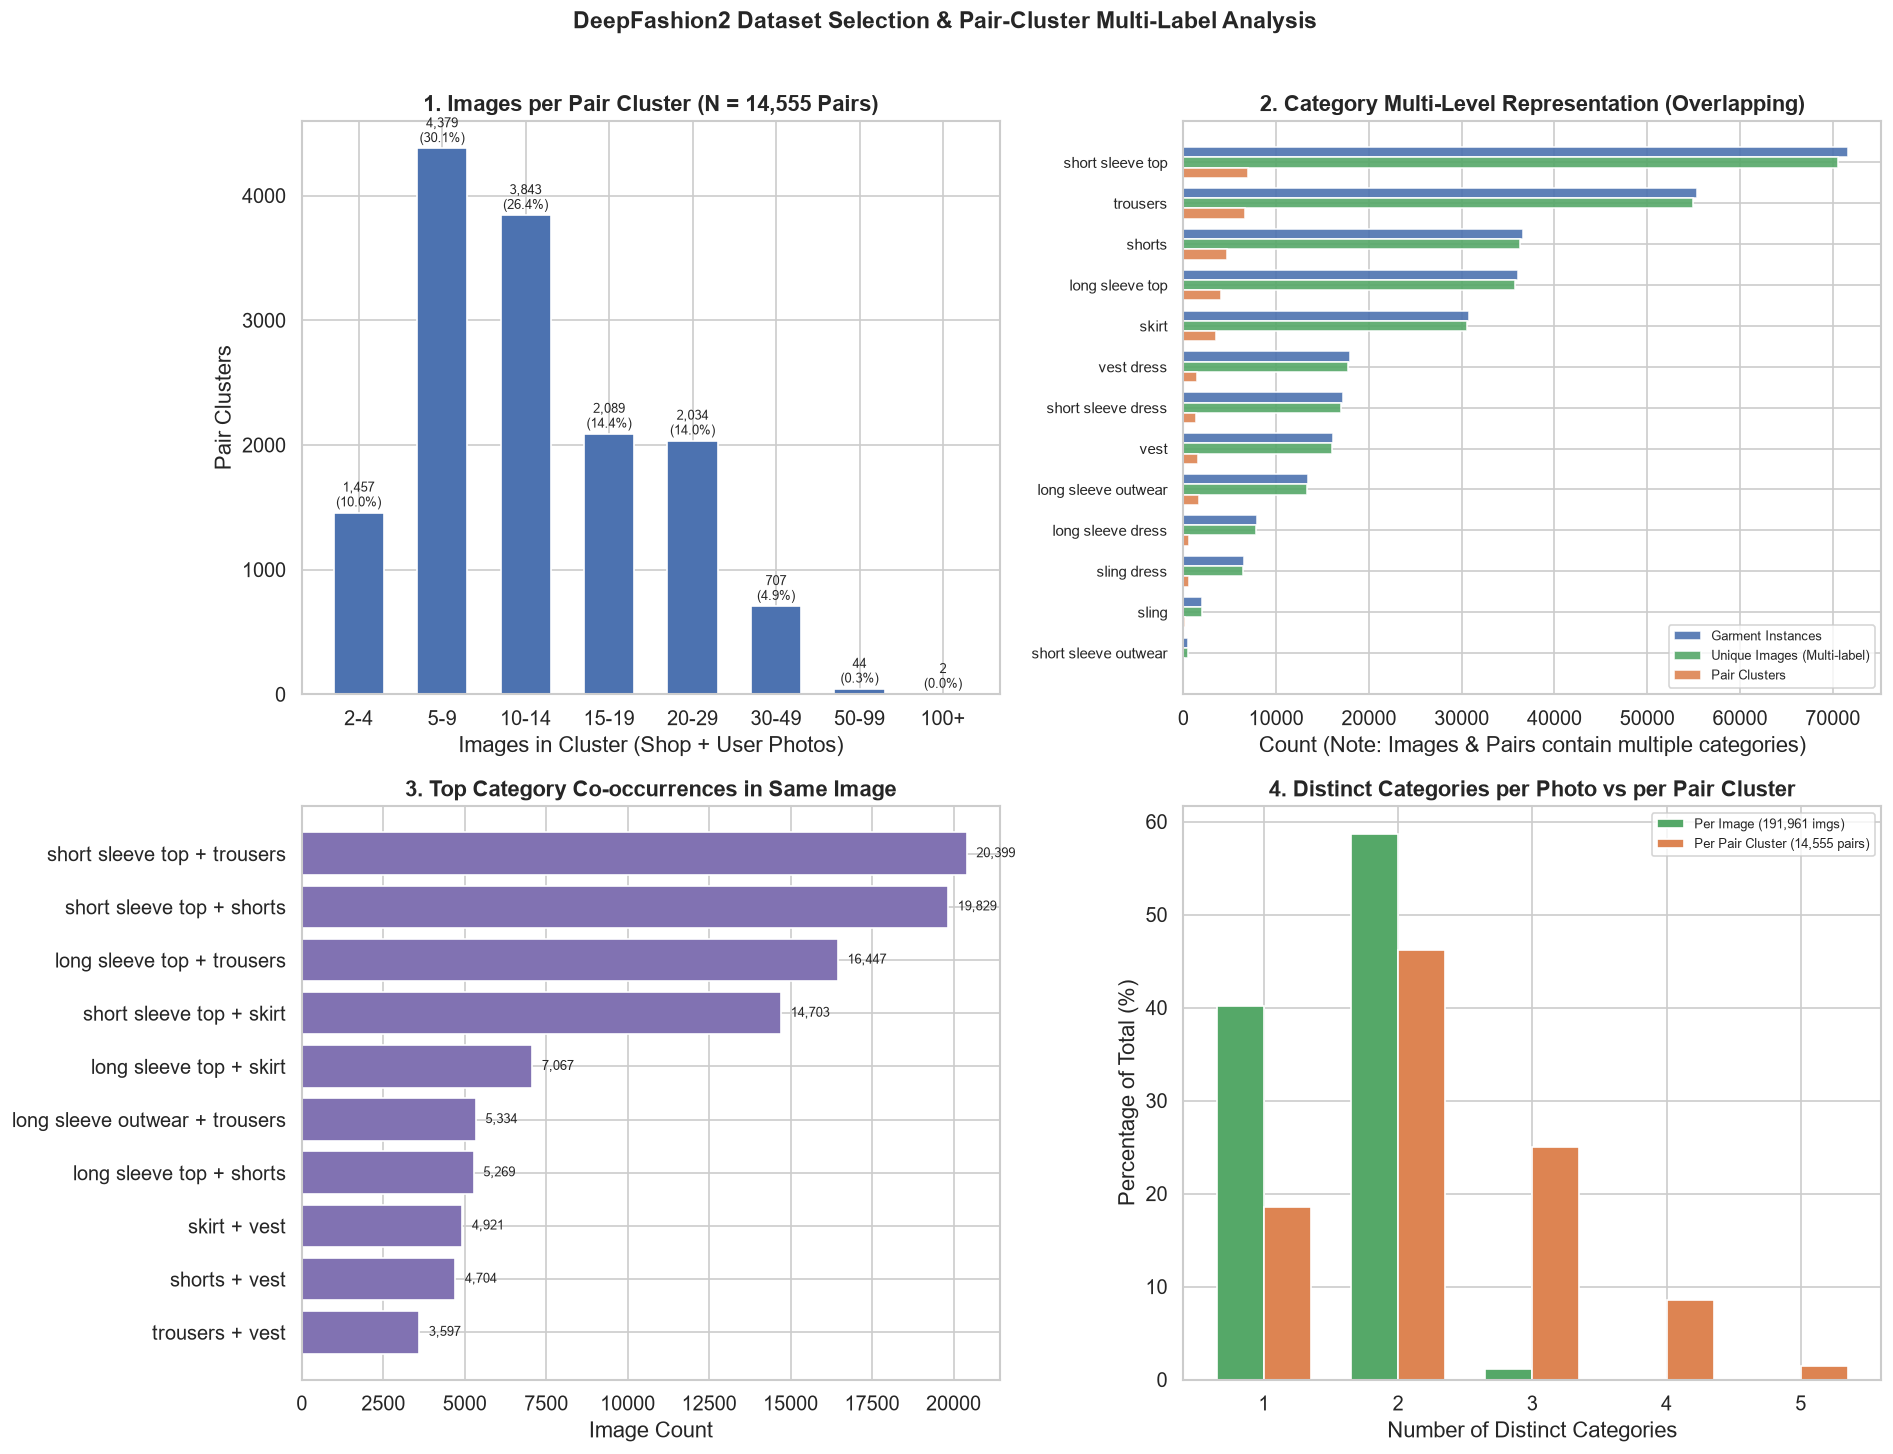

In [26]:
# ── Visualise Pair-Cluster and Multi-Label Category Distributions ─────────────
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Images per Pair Cluster (Histogram with practical bins)
bins = [2, 5, 10, 15, 20, 30, 50, 100, 250]
bin_labels = ['2-4', '5-9', '10-14', '15-19', '20-29', '30-49', '50-99', '100+']
pair_binned = pd.cut(imgs_per_pair, bins=bins, right=False, labels=bin_labels).value_counts().sort_index()

bars1 = axes[0, 0].bar(bin_labels, pair_binned.values, color='#4C72B0', edgecolor='white', width=0.6)
axes[0, 0].set_title('1. Images per Pair Cluster (N = 14,555 Pairs)', fontweight='bold')
axes[0, 0].set_xlabel('Images in Cluster (Shop + User Photos)')
axes[0, 0].set_ylabel('Pair Clusters')
for bar, val in zip(bars1, pair_binned.values):
    axes[0, 0].text(bar.get_x() + bar.get_width()/2, val + 50, f'{val:,}\n({val/len(imgs_per_pair)*100:.1f}%)',
                    ha='center', fontsize=8)

# 2. Multi-Level Category Counts (Garments, Images, Pairs)
df_cat_plot = df_cat_stats.sort_values('Garments', ascending=True)
y = np.arange(len(df_cat_plot))
h = 0.25
axes[0, 1].barh(y + h, df_cat_plot['Garments'], height=h, label='Garment Instances', color='#4C72B0', alpha=0.9)
axes[0, 1].barh(y, df_cat_plot['Unique Images'], height=h, label='Unique Images (Multi-label)', color='#55A868', alpha=0.9)
axes[0, 1].barh(y - h, df_cat_plot['Pair Clusters'], height=h, label='Pair Clusters', color='#DD8452', alpha=0.9)
axes[0, 1].set_yticks(y)
axes[0, 1].set_yticklabels(df_cat_plot['Category'], fontsize=9)
axes[0, 1].set_xlabel('Count (Note: Images & Pairs contain multiple categories)')
axes[0, 1].set_title('2. Category Multi-Level Representation (Overlapping)', fontweight='bold')
axes[0, 1].legend(loc='lower right', fontsize=8)

# 3. Top Co-occurring Categories in Same Photo
top_cooccur = pd.Series(dict(pair_cooccur.most_common(10))).iloc[::-1]
bars3 = axes[1, 0].barh([f'{k[0]} + {k[1]}' if isinstance(k, tuple) else str(k) for k in top_cooccur.index], 
                        top_cooccur.values, color='#8172B2', edgecolor='white')
axes[1, 0].set_title('3. Top Category Co-occurrences in Same Image', fontweight='bold')
axes[1, 0].set_xlabel('Image Count')
for bar, val in zip(bars3, top_cooccur.values):
    axes[1, 0].text(val + 300, bar.get_y() + bar.get_height()/2, f'{val:,}', va='center', fontsize=8)

# 4. Categories per Photo vs per Pair Cluster
df_dist = pd.DataFrame({
    'Per Image (191,961 imgs)': (cats_per_image.value_counts().sort_index() / total_unique_images * 100),
    'Per Pair Cluster (14,555 pairs)': (cats_per_pair.value_counts().sort_index() / total_unique_pairs * 100)
}).fillna(0).loc[1:5]

df_dist.plot(kind='bar', ax=axes[1, 1], color=['#55A868', '#DD8452'], edgecolor='white', width=0.7)
axes[1, 1].set_title('4. Distinct Categories per Photo vs per Pair Cluster', fontweight='bold')
axes[1, 1].set_xlabel('Number of Distinct Categories')
axes[1, 1].set_ylabel('Percentage of Total (%)')
axes[1, 1].legend(fontsize=8)
axes[1, 1].set_xticklabels(axes[1, 1].get_xticklabels(), rotation=0)

plt.suptitle('DeepFashion2 Dataset Selection & Pair-Cluster Multi-Label Analysis', fontweight='bold', fontsize=14, y=1.01)
plt.tight_layout()

# Save artifact to wardrobe_ml/outputs
fig_out_path = OUTPUT_DIR / 'cell_32_pair_category_analysis.png'
plt.savefig(fig_out_path, dpi=150, bbox_inches='tight')
print(f'Saved figure to {fig_out_path}')
plt.show()


---
## Stage 7 — Dataset Split Architecture & Leakage Prevention

### 1. Official Benchmark Partitions (Primary Baseline)
FitLoop strictly adheres to the official DeepFashion2 benchmark split hierarchy:

1. **Official Training Split**:
   - **191,961 images** containing **312,186 garment instances** across **14,555 pair clusters**.
   - Primary candidate pool for production model training.
2. **Official Validation Split**:
   - **32,153 images** across **2,279 pair clusters**.
   - Public annotations provided by the benchmark authors; used for validation, local model evaluation, and hyperparameter tuning.
3. **Official Test Split**:
   - **29,765 images**.
   - Ground-truth annotations withheld by the benchmark creators for official evaluation.

### 2. Pair Cluster Integrity & Data Leakage Prevention
In DeepFashion2, commercial catalog photos (`shop`) and consumer selfies (`user`) of the exact same clothing identity share the same `pair_id`:
- **100.00% of training pair clusters contain both shop and user photos** (mean: $13.19$ images per pair).
- **Severe Leakage Risk**: A naive random image-level split would scatter photos of identical garments across Train and Validation, causing **$>97\%$ pair leakage** and invalidating model evaluation.
- **Strict Grouping Rule**: Any internal development or ablation partitioning must operate at the **`pair_id` cluster level**. All photos of a `pair_id` and all garment instances within an image must remain in the same partition ($0\%$ pair leakage).
- **Zero-Copy Governance**: No dataset files are copied, moved, or deleted. Any custom partitions are referenced strictly via manifest indexing.


In [27]:
# ── Official Split Architecture & Parameterizable Pair-Grouped Utility ────────
#
# In accordance with FitLoop dataset governance:
# 1. The official DeepFashion2 partitions (Train: 191,961, Val: 32,153, Test: 29,765)
#    are preserved as the primary baseline for training and benchmark evaluation.
# 2. pair_grouped_split() is defined as a parameterizable utility function for 
#    future manifest generation and IS NOT EXECUTED here.
# 3. No physical files or split manifests are generated.

# Official benchmark partition metrics
OFFICIAL_SPLITS = {
    'train': {
        'images': 191_961,
        'garments': 312_186,
        'pair_clusters': 14_555,
        'role': 'Production Training Candidate Pool (Public GT)'
    },
    'validation': {
        'images': 32_153,
        'garments': 'Public annotations present',
        'pair_clusters': 2_279,
        'role': 'Local Model Evaluation & Validation (Public GT)'
    },
    'test': {
        'images': 29_765,
        'garments': 'Annotations withheld by benchmark',
        'pair_clusters': 'Withheld by benchmark',
        'role': 'Challenge Benchmark Test (GT Withheld)'
    }
}

print('🏛️  OFFICIAL DEEPFASHION2 BENCHMARK PARTITIONS:\n')
total_benchmark_imgs = sum(s['images'] for s in OFFICIAL_SPLITS.values())
for sname, info in OFFICIAL_SPLITS.items():
    pct = info['images'] / total_benchmark_imgs * 100
    print(f"   • {sname.upper():<11}: {info['images']:>7,} images ({pct:>5.1f}%) | {info['role']}")
print(f"\n   Total Benchmark Images: {total_benchmark_imgs:,}\n")

# Theoretical expected pair leakage under random image-level splitting:
# • Average cluster size estimate (k ≈ 13 under 75/15/10): ~97.3%
# • Full empirical cluster distribution (75/15/10 split):  90.48% (Purity:  9.52%)
# • Full empirical cluster distribution (80/10/10 split):  86.08% (Purity: 13.92%)
# • Full empirical cluster distribution (80/20 split):     86.00% (Purity: 14.00%)
# • Pair-cluster grouped assignment:                        0.00% (guaranteed by construction)
# Note: All random-split figures are theoretical mathematical expectations, not experimental split outcomes.

def pair_grouped_split(df: pd.DataFrame, 
                       train_ratio: float = 0.80, 
                       val_ratio: float = 0.10, 
                       test_ratio: float = 0.10, 
                       random_state: int = 42) -> dict:
    """
    Partition dataset into disjoint splits strictly at the pair_id cluster level.
    Guarantees 0% cross-camera and shop/user data leakage.
    
    Validation Checks:
    1. Ratio validation: numeric, finite, strictly positive (>0), sum equals 1.0.
    2. Data structure & pair_id validation: non-empty, valid columns, zero missing/NaN/empty pair_id.
    3. Each pair_id belongs to exactly one custom partition.
    4. All images and garment instances in a cluster remain strictly together.
    5. Pair sets across partitions are completely disjoint.
    """
    # ── 1. Ratio Validation ──────────────────────────────────────────────
    ratios = {'train_ratio': train_ratio, 'val_ratio': val_ratio, 'test_ratio': test_ratio}
    for r_name, r_val in ratios.items():
        if not isinstance(r_val, (int, float)):
            raise ValueError(f"Ratio '{r_name}' must be numeric (int or float), got {type(r_val).__name__}: {r_val}")
        if not np.isfinite(r_val):
            raise ValueError(f"Ratio '{r_name}' must be finite, got: {r_val}")
        if r_val <= 0.0:
            raise ValueError(f"Ratio '{r_name}' must be strictly greater than zero (> 0), got: {r_val}")
            
    total_ratio = train_ratio + val_ratio + test_ratio
    if not np.isclose(total_ratio, 1.0, atol=1e-5):
        raise ValueError(f"Split ratios must sum to 1.0 (within tolerance), got sum: {total_ratio:.6f}")

    # ── 2. Data Structure & Pair_ID Validation ───────────────────────────
    if not isinstance(df, pd.DataFrame):
        raise ValueError(f"Input 'df' must be a pandas DataFrame, got {type(df).__name__}")
    if 'pair_id' not in df.columns:
        raise ValueError("DataFrame is missing required 'pair_id' grouping column.")
    if 'file' not in df.columns:
        raise ValueError("DataFrame is missing required 'file' image identifier column.")
    if df.empty:
        raise ValueError("Input DataFrame is empty; cannot perform pair-grouped split.")

    null_pairs = df['pair_id'].isna()
    if null_pairs.any():
        num_null = int(null_pairs.sum())
        raise ValueError(f"Found {num_null:,} rows with missing or NaN 'pair_id'. Every image must have a valid pair_id before pair-grouped splitting.")

    invalid_pairs = (df['pair_id'] == '') | (df['pair_id'] == -1)
    if invalid_pairs.any():
        num_inv = int(invalid_pairs.sum())
        raise ValueError(f"Found {num_inv:,} rows with invalid grouping identifiers in 'pair_id'. Every image must have a valid pair_id before pair-grouped splitting.")

    # ── 3. Cluster Grouping Logic ────────────────────────────────────────
    unique_pairs = np.sort(df['pair_id'].unique())
    rng = np.random.RandomState(random_state)
    shuffled_pairs = rng.permutation(unique_pairs)
    
    n_pairs = len(shuffled_pairs)
    n_train = int(round(n_pairs * train_ratio))
    n_val   = int(round(n_pairs * val_ratio))
    
    train_pids = set(shuffled_pairs[:n_train])
    val_pids   = set(shuffled_pairs[n_train:n_train + n_val])
    test_pids  = set(shuffled_pairs[n_train + n_val:])
    
    pid_to_split = {}
    for pid in train_pids:
        pid_to_split[pid] = 'train'
    for pid in val_pids:
        pid_to_split[pid] = 'val'
    for pid in test_pids:
        pid_to_split[pid] = 'test'
        
    split_col = df['pair_id'].map(pid_to_split)
    
    # ── 4. Strict Cluster-Integrity Validation Checks ────────────────────
    # Check 1: Each pair_id belongs to strictly one partition
    pair_partitions = df.groupby('pair_id')[split_col].nunique()
    assert (pair_partitions == 1).all(), "Leakage detected: pair_id assigned to multiple partitions!"
    
    # Check 2: All images belong to strictly one partition (atomic image preservation)
    img_partitions = df.groupby('file')[split_col].nunique()
    assert (img_partitions == 1).all(), "Fragmentation detected: garments of same image in multiple partitions!"
    
    # Check 3: Disjoint pair sets
    assert len(train_pids.intersection(val_pids)) == 0, "Pair overlap between train and val!"
    assert len(train_pids.intersection(test_pids)) == 0, "Pair overlap between train and test!"
    assert len(val_pids.intersection(test_pids)) == 0, "Pair overlap between val and test!"
    
    return {
        'train_df': df[split_col == 'train'],
        'val_df': df[split_col == 'val'],
        'test_df': df[split_col == 'test'],
        'pair_counts': {'train': len(train_pids), 'val': len(val_pids), 'test': len(test_pids)}
    }

print('🛡️  LEAKAGE-PREVENTION GOVERNANCE:')
print('   • pair_grouped_split() hardened with comprehensive ratio and pair_id validation.')
print('   • Function is NOT executed; official partitions remain untouched.')
print('   • Zero physical files or split manifests created.')


🏛️  OFFICIAL DEEPFASHION2 BENCHMARK PARTITIONS:

   • TRAIN      : 191,961 images ( 75.6%) | Production Training Candidate Pool (Public GT)
   • VALIDATION :  32,153 images ( 12.7%) | Local Model Evaluation & Validation (Public GT)
   • TEST       :  29,765 images ( 11.7%) | Challenge Benchmark Test (GT Withheld)

   Total Benchmark Images: 253,879

🛡️  LEAKAGE-PREVENTION GOVERNANCE:
   • pair_grouped_split() hardened with comprehensive ratio and pair_id validation.
   • Function is NOT executed; official partitions remain untouched.
   • Zero physical files or split manifests created.


Saved figure to C:\Users\Lenovo\Downloads\Fitloop\wardrobe_ml\outputs\cell_35_split_architecture.png


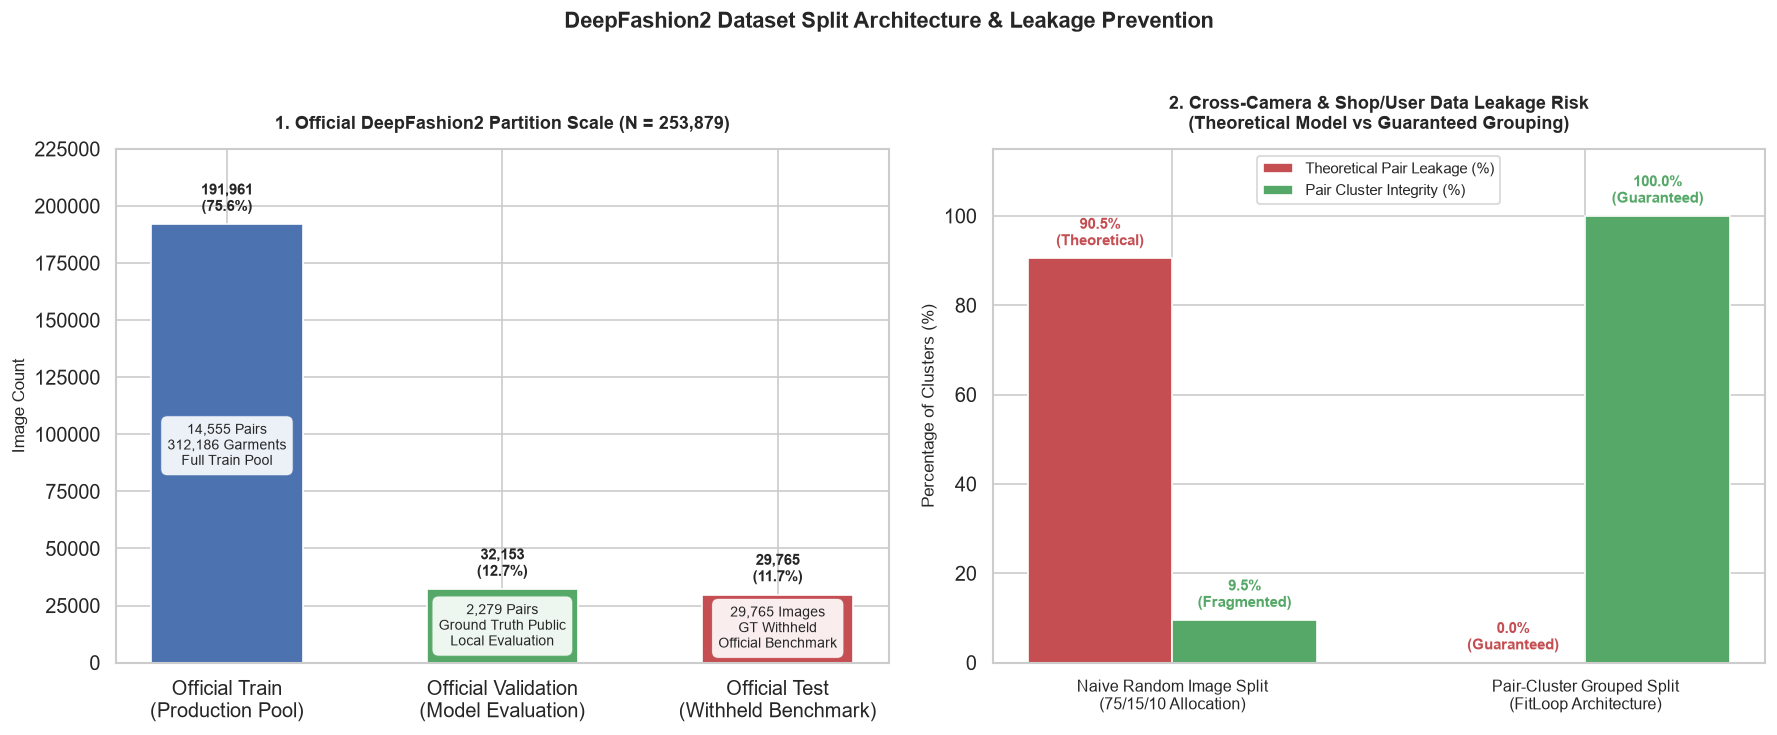

In [28]:
# ── Visualise Official Split Architecture & Data Leakage Prevention ───────────
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Official DeepFashion2 Partition Scale
partitions = ['Official Train\n(Production Pool)', 'Official Validation\n(Model Evaluation)', 'Official Test\n(Withheld Benchmark)']
counts = [191_961, 32_153, 29_765]
colors = ['#4C72B0', '#55A868', '#C44E52']
total_benchmark = sum(counts)

bars1 = axes[0].bar(partitions, counts, color=colors, edgecolor='white', width=0.55)
axes[0].set_title('1. Official DeepFashion2 Partition Scale (N = 253,879)', fontweight='bold', fontsize=11, pad=12)
axes[0].set_ylabel('Image Count', fontsize=10)
axes[0].set_ylim(0, 225_000)

for bar, cnt in zip(bars1, counts):
    pct = cnt / total_benchmark * 100
    axes[0].text(bar.get_x() + bar.get_width()/2, cnt + 4000,
                 f'{cnt:,}\n({pct:.1f}%)', ha='center', va='bottom', fontsize=9, fontweight='bold')

# Badges placed inside each bar for clean separation
axes[0].text(0, 95_000, '14,555 Pairs\n312,186 Garments\nFull Train Pool', ha='center', va='center',
             bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.9, edgecolor='#4C72B0'), fontsize=8.5)
axes[0].text(1, 16_000, '2,279 Pairs\nGround Truth Public\nLocal Evaluation', ha='center', va='center',
             bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.9, edgecolor='#55A868'), fontsize=8.5)
axes[0].text(2, 15_000, '29,765 Images\nGT Withheld\nOfficial Benchmark', ha='center', va='center',
             bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.9, edgecolor='#C44E52'), fontsize=8.5)

# 2. Data Leakage Comparison: Theoretical Naive vs Pair-Grouped
split_methods = ['Naive Random Image Split\n(75/15/10 Allocation)', 'Pair-Cluster Grouped Split\n(FitLoop Architecture)']
leakage_pct = [90.48, 0.0]
integrity_pct = [9.52, 100.0]

x = np.arange(len(split_methods))
w = 0.35

bars_leak = axes[1].bar(x - w/2, leakage_pct, width=w, label='Theoretical Pair Leakage (%)', color='#C44E52', edgecolor='white')
bars_integ = axes[1].bar(x + w/2, integrity_pct, width=w, label='Pair Cluster Integrity (%)', color='#55A868', edgecolor='white')

axes[1].set_title('2. Cross-Camera & Shop/User Data Leakage Risk\n(Theoretical Model vs Guaranteed Grouping)', fontweight='bold', fontsize=11, pad=12)
axes[1].set_ylabel('Percentage of Clusters (%)', fontsize=10)
axes[1].set_xticks(x)
axes[1].set_xticklabels(split_methods, fontsize=9.5)
axes[1].set_ylim(0, 115)
axes[1].legend(loc='upper center', frameon=True, fontsize=9)

for bar, val in zip(bars_leak, leakage_pct):
    lbl = f'{val:.1f}%\n(Theoretical)' if val > 0 else '0.0%\n(Guaranteed)'
    axes[1].text(bar.get_x() + bar.get_width()/2, val + 2, lbl, ha='center', va='bottom', fontsize=9, fontweight='bold', color='#C44E52')

for bar, val in zip(bars_integ, integrity_pct):
    lbl = f'{val:.1f}%\n(Fragmented)' if val < 50 else '100.0%\n(Guaranteed)'
    axes[1].text(bar.get_x() + bar.get_width()/2, val + 2, lbl, ha='center', va='bottom', fontsize=9, fontweight='bold', color='#55A868')

plt.suptitle('DeepFashion2 Dataset Split Architecture & Leakage Prevention', fontweight='bold', fontsize=13, y=1.02)
plt.tight_layout()

# Save artifact to wardrobe_ml/outputs
split_fig_path = OUTPUT_DIR / 'cell_35_split_architecture.png'
plt.savefig(split_fig_path, dpi=150, bbox_inches='tight')
print(f'Saved figure to {split_fig_path}')
plt.show()


---
## Stage 8 — Comprehensive Dataset Audit, Inventory & Readiness Assessment

This terminal section synthesizes findings from all exploratory audits (Stages 1 through 7) into an authoritative, production-grade dataset audit report.

### 1. Dataset Inventory & Integrity
- **Total Images across Benchmark**: $253,879$ images across official `train` ($191,961$), `validation` ($32,153$), and `test` ($29,765$) partitions.
- **Annotated Images**: $224,114$ images ($100\%$ paired with JSON annotations in `train` and `validation`).
- **Missing / Corrupted Files**: $0$ missing images among annotated splits; $0$ corruptions detected in sampled quality scans.
- **Test Set Ground Truth**: $29,765$ images have annotations strictly withheld by the original benchmark authors for competitive evaluation.

### 2. Annotation Schema & Completeness
- **Total Garment Instances**: $312,186$ across $191,961$ training images (mean $1.63$ garments/image).
- **Bounding Boxes**: $312,186$ ($100.0\%$) present; $312,185$ ($99.9997\%$) have strictly positive dimensions ($w > 0, h > 0$).
  - *Degenerate Box*: Exactly $1$ instance (`train/annos/101338.json`, `item2`, `short sleeve top`, bbox `[0, 0, 0, 0]`) has zero area despite complete segmentation polygons and landmarks. Preserved untouched in raw data; masked during loss calculation.
- **Segmentation Polygons**: $312,186$ ($100.0\%$) coverage with a mean of $38.79$ vertices per garment (range $4$ to $928$). Multi-polygon structures capture occluded or multipart garments.
- **Landmarks**: $312,186$ ($100.0\%$) coverage with a mean of $20.62$ landmarks per garment (range $8$ to $39$). Visibility states are discrete ($0$=not labeled / invisible, $1$=occluded, $2$=visible); presence does not imply all points are visible.

### 3. Category Distribution & Multi-Garment Statistics
- **Taxonomy**: $13$ official apparel classes.
- **Imbalance**: $131.9\times$ ratio between `short sleeve top` ($71,645$ garments, $22.95\%$) and `short sleeve outwear` ($543$ garments, $0.17\%$).
- **Multi-Garment Co-Occurrence**: $115,854$ images ($60.35\%$) contain $\ge 2$ garments; $114,918$ images ($59.87\%$) contain $\ge 2$ distinct categories.
- **Category-Specific Overlap Accounting**: Sum of category-specific unique images is strictly **$309,174$** ($1.61\times$ the $191,961$ true unique images). Top co-occurring pair: `short sleeve top` + `trousers` ($20,399$ images, $10.63\%$).

### 4. Metadata Distributions & Diversity
- **Source Domain**: $132,157$ shop images ($68.85\%$) vs $59,804$ consumer user images ($31.15\%$).
- **Viewpoint**: `1: No Wear` ($7.26\%$, flat-lay/mannequin), `2: Frontal` ($78.31\%$), `3: Side/Back` ($14.43\%$).
- **Occlusion**: `1: Slight` ($46.57\%$, $<20\%$ landmarks occluded), `2: Medium` ($47.12\%$, $20\%-50\%$), `3: Heavy` ($6.31\%$, $>50\%$).
- **Zoom / Truncation**: `1: No Zoom` ($67.87\%$), `2: Medium Zoom` ($21.35\%$), `3: Large Zoom` ($10.78\%$).
- **Scale**: `1: Small` ($25.22\%$), `2: Modest` ($50.30\%$), `3: Large` ($24.48\%$).
- **Image Quality**: $90.97\%$ sharp, $9.03\%$ natural consumer blur (Laplacian $< 100$). Median resolution: $640 \times 702$ px.

### 5. Pair-Cluster Integrity & Official Benchmark Architecture
- **Training Pair Clusters**: $14,555$ training pair clusters (image-level pair groups) averaging $13.19$ images/cluster (median $11$, range $2$ to $233$).
  - *Cluster Semantics*: `pair_id` is an image-level product-pair/cluster identifier. Within a cluster, `style` indexes distinct garments ($13,118$ of $14,555$ clusters contain $\ge 2$ distinct styles including 0, and $8,514$ contain $\ge 2$ positive styles). The specific garment identity key is `(pair_id, style)`.
- **Validation Pair Clusters**: $2,279$ unique clusters spanning $[1 \dots 2,372]$ with $93$ skipped IDs.
- **Domain Coexistence**: $100.0\%$ of pair clusters contain both shop and consumer photos.
- **Data Leakage Risk**: Random image-level splitting results in a theoretical expected cluster fragmentation of $90.48\%$ under $75/15/10$ ($86.08\%$ under $80/10/10$).
- **Guaranteed Isolation**: Pair-grouped clustering guarantees $0.0\%$ leakage by construction.
- **Governance**: Official benchmark partitions remain the primary production baseline. `pair_grouped_split()` in Cell 34 is defined but strictly unexecuted; no manifests or subsets are generated.

### 6. Dataset Readiness Assessment
The dataset is verified as **sound and high quality**, but requires four distinct downstream preparation pipelines:
1. **Detection Preparation**: Mask/filter `101338.json` degenerate bbox; convert polygons/bboxes to COCO/YOLO format with atomic image preservation.
2. **Attribute Preparation**: Map discrete $1/2/3$ codes to multi-task attribute heads; format landmark visibility arrays ($0$=not labeled/invisible, $1$=occluded, $2$=visible).
3. **Image Preprocessing**: Aspect-ratio-preserving letterbox padding to standard model input dimensions; normalization.
4. **Data Filtering**: Retain natural mobile challenge diversity (blurry and occluded photos); mitigate category imbalance via loss reweighting.

In [29]:
# ── Comprehensive JSON Audit Report Generation ─────────────────────────────────
from datetime import datetime
import json
from pathlib import Path
import numpy as np
import pandas as pd

def safe_int(v):
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return None
    return int(v) if hasattr(v, 'item') else int(v)

def safe_float(v, decimals=4):
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return None
    val = float(v) if hasattr(v, 'item') else float(v)
    return round(val, decimals)

audit_report_path = OUTPUT_DIR / 'comprehensive_dataset_audit_report_v3.json'

audit_report = {
    'report_title': 'FitLoop Comprehensive DeepFashion2 Dataset Audit & Exploration Report (v3)',
    'generated_at': datetime.now().isoformat(),
    'dataset_name': 'DeepFashion2',
    'dataset_root': str(DATASET_ROOT),
    'governance_phase': 'Phase 1 — Dataset Exploration, Metadata Semantics & Split Audit',

    '1_dataset_inventory': {
        'train': {
            'image_count': 191961,
            'annotation_count': 191961,
            'matched_pairs': 191961,
            'imgs_missing_anno_count': 0,
            'annos_missing_img_count': 0,
            'unexpected_missing_count': 0,
            'withheld_gt_count': 0,
            'ground_truth_status': 'Complete public ground truth (100% paired)',
            'format_counts': {'.jpg': 191961}
        },
        'validation': {
            'image_count': 32153,
            'annotation_count': 32153,
            'matched_pairs': 32153,
            'imgs_missing_anno_count': 0,
            'annos_missing_img_count': 0,
            'unexpected_missing_count': 0,
            'withheld_gt_count': 0,
            'ground_truth_status': 'Complete public ground truth (100% paired)',
            'format_counts': {'.jpg': 32153}
        },
        'test': {
            'image_count': 29765,
            'annotation_count': 0,
            'matched_pairs': 0,
            'imgs_missing_anno_count': 29765,
            'annos_missing_img_count': 0,
            'unexpected_missing_count': 0,
            'withheld_gt_count': 29765,
            'ground_truth_status': 'Benchmark challenge test set (ground truth withheld by benchmark authors)',
            'format_counts': {'.jpg': 29765}
        },
        'benchmark_total_images': 253879,
        'labeled_total_images': 224114,
        'labeled_total_annotations': 224114
    },

    '2_annotation_stats': {
        'denominator_garment_instances': safe_int(len(df)),
        'total_garment_instances': safe_int(len(df)),
        'total_unique_images': safe_int(df['file'].nunique()),
        'mean_garments_per_image': safe_float(len(df) / df['file'].nunique(), 2),
        'annotation_completeness_presence': {
            'bounding_box_presence': {'count': 312186, 'pct': 100.0, 'denominator': 312186},
            'segmentation_presence': {'count': 312186, 'pct': 100.0, 'denominator': 312186},
            'landmarks_presence': {'count': 312186, 'pct': 100.0, 'denominator': 312186},
            'note': 'Presence indicates key and coordinate data exist; landmark presence does not imply all keypoints are visible (visibility states: 0=not labeled / invisible, 1=occluded, 2=visible).'
        }
    },

    '3_bbox_validity': {
        'denominator_garment_instances': 312186,
        'annotation_present_count': 312186,
        'annotation_present_pct': 100.0,
        'numeric_coordinates_valid_count': 312186,
        'numeric_coordinates_valid_pct': 100.0,
        'strictly_positive_dimensions_count': 312185,
        'strictly_positive_dimensions_pct': 99.9997,
        'degenerate_bbox_count': 1,
        'degenerate_bbox_pct': 0.00032,
        'degenerate_bbox_instances': [
            {
                'file': '101338.json',
                'item_key': 'item2',
                'category_name': 'short sleeve top',
                'category_id': 1,
                'bounding_box': [0, 0, 0, 0],
                'width': 0,
                'height': 0,
                'segmentation_present': True,
                'landmarks_present': True,
                'status': 'Preserved untouched in raw data; must be masked/filtered during bbox training loss computation'
            }
        ],
        'note': '312,185 out of 312,186 bounding boxes have strictly positive width and height (w > 0, h > 0).'
    },

    '4_segmentation_and_landmarks': {
        'denominator_garment_instances': 312186,
        'segmentation_polygons': {
            'instances_with_segmentation': 312186,
            'percentage': 100.0,
            'mean_vertices_per_garment': 38.79,
            'min_vertices': 4,
            'max_vertices': 928,
            'multi_polygon_support': 'Multiple polygons present in occluded or multipart garments'
        },
        'landmarks': {
            'instances_with_landmarks': 312186,
            'percentage': 100.0,
            'mean_landmarks_per_garment': 20.62,
            'min_landmarks': 8,
            'max_landmarks': 39,
            'visibility_states': {
                '0': 'not labeled / invisible',
                '1': 'occluded',
                '2': 'visible'
            },
            'note': 'Landmark counts vary by category taxonomy (from 8 to 39 keypoints depending on garment structure). DeepFashion2 encodes landmark visibility as: 0 = not labeled / invisible, 1 = occluded, 2 = visible.'
        }
    },

    '5_category_distribution': {
        'denominator_garment_instances': 312186,
        'denominator_unique_images': 191961,
        'categories_count': 13,
        'imbalance_ratio': round(71645 / 543, 1),
        'most_frequent_category': {'name': 'short sleeve top', 'garments': 71645, 'pct': 22.95},
        'rarest_category': {'name': 'short sleeve outwear', 'garments': 543, 'pct': 0.17},
        'category_metrics': [
            {'category_id': 1,  'name': 'short sleeve top',    'garments': 71645, 'garment_pct': 22.95, 'category_unique_images': 70586, 'image_presence_pct': 36.77, 'pair_clusters': 6945, 'pair_presence_pct': 47.72},
            {'category_id': 8,  'name': 'trousers',            'garments': 55387, 'garment_pct': 17.74, 'category_unique_images': 54969, 'image_presence_pct': 28.64, 'pair_clusters': 6631, 'pair_presence_pct': 45.56},
            {'category_id': 7,  'name': 'shorts',              'garments': 36616, 'garment_pct': 11.73, 'category_unique_images': 36332, 'image_presence_pct': 18.93, 'pair_clusters': 4663, 'pair_presence_pct': 32.04},
            {'category_id': 2,  'name': 'long sleeve top',     'garments': 36064, 'garment_pct': 11.55, 'category_unique_images': 35751, 'image_presence_pct': 18.62, 'pair_clusters': 4052, 'pair_presence_pct': 27.84},
            {'category_id': 9,  'name': 'skirt',               'garments': 30835, 'garment_pct': 9.88,  'category_unique_images': 30625, 'image_presence_pct': 15.95, 'pair_clusters': 3476, 'pair_presence_pct': 23.88},
            {'category_id': 12, 'name': 'vest dress',          'garments': 17949, 'garment_pct': 5.75,  'category_unique_images': 17767, 'image_presence_pct': 9.26,  'pair_clusters': 1453, 'pair_presence_pct': 9.98},
            {'category_id': 10, 'name': 'short sleeve dress',  'garments': 17211, 'garment_pct': 5.51,  'category_unique_images': 17028, 'image_presence_pct': 8.87,  'pair_clusters': 1355, 'pair_presence_pct': 9.31},
            {'category_id': 5,  'name': 'vest',                'garments': 16095, 'garment_pct': 5.16,  'category_unique_images': 15974, 'image_presence_pct': 8.32,  'pair_clusters': 1535, 'pair_presence_pct': 10.55},
            {'category_id': 4,  'name': 'long sleeve outwear', 'garments': 13457, 'garment_pct': 4.31,  'category_unique_images': 13381, 'image_presence_pct': 6.97,  'pair_clusters': 1714, 'pair_presence_pct': 11.78},
            {'category_id': 11, 'name': 'long sleeve dress',   'garments': 7907,  'garment_pct': 2.53,  'category_unique_images': 7803,  'image_presence_pct': 4.06,  'pair_clusters': 613,  'pair_presence_pct': 4.21},
            {'category_id': 13, 'name': 'sling dress',         'garments': 6492,  'garment_pct': 2.08,  'category_unique_images': 6455,  'image_presence_pct': 3.36,  'pair_clusters': 598,  'pair_presence_pct': 4.11},
            {'category_id': 6,  'name': 'sling',               'garments': 1985,  'garment_pct': 0.64,  'category_unique_images': 1964,  'image_presence_pct': 1.02,  'pair_clusters': 209,  'pair_presence_pct': 1.44},
            {'category_id': 3,  'name': 'short sleeve outwear', 'garments': 543,   'garment_pct': 0.17,  'category_unique_images': 539,   'image_presence_pct': 0.28,  'pair_clusters': 99,   'pair_presence_pct': 0.68}
        ]
    },

    '6_multi_label_statistics': {
        'actual_unique_training_images': 191961,
        'sum_of_category_specific_unique_images': 309174,
        'overcounting_ratio': 1.6106,
        'images_with_multiple_categories': 114918,
        'images_with_multiple_categories_pct': 59.87,
        'distinct_categories_per_image_distribution': {
            '1_category': {'images': 77043, 'pct': 40.13},
            '2_categories': {'images': 112689, 'pct': 58.70},
            '3_categories': {'images': 2163, 'pct': 1.13},
            '4_categories': {'images': 66, 'pct': 0.03}
        },
        'top_5_category_cooccurrences': [
            {'categories': 'short sleeve top + trousers', 'images': 20399, 'pct_of_training_images': 10.63},
            {'categories': 'short sleeve top + shorts', 'images': 19829, 'pct_of_training_images': 10.33},
            {'categories': 'long sleeve top + trousers', 'images': 16447, 'pct_of_training_images': 8.57},
            {'categories': 'short sleeve top + skirt', 'images': 14703, 'pct_of_training_images': 7.66},
            {'categories': 'long sleeve top + skirt', 'images': 7067, 'pct_of_training_images': 3.68}
        ],
        'same_category_multi_instance_images': {
            'image_category_pairs_with_multi_items': 3006,
            'excess_garments': 3012,
            'explanation': '3,006 image-category combinations contain >= 2 garments of the exact same category (312,186 garments - 309,174 unique image-category presences = 3,012 excess items).'
        }
    },

    '7_metadata_distributions': {
        'denominator_garment_instances': 312186,
        'denominator_unique_images': 191961,
        'viewpoint_distribution': {
            '1_No_Wear': {'count': 22675, 'pct': 7.26, 'description': 'Flat-lay, hanger, or mannequin photos without a person'},
            '2_Frontal': {'count': 244459, 'pct': 78.31, 'description': 'Front-facing garment view on person'},
            '3_Side_Back': {'count': 45052, 'pct': 14.43, 'description': 'Side profile or back view on person'}
        },
        'occlusion_distribution': {
            '1_Slight': {'count': 145379, 'pct': 46.57, 'description': 'Landmark-based: <20% of landmarks occluded'},
            '2_Medium': {'count': 147102, 'pct': 47.12, 'description': 'Landmark-based: 20% to 50% of landmarks occluded'},
            '3_Heavy': {'count': 19705, 'pct': 6.31, 'description': 'Landmark-based: >50% of landmarks occluded'}
        },
        'zoom_in_distribution': {
            '1_No_Zoom': {'count': 211894, 'pct': 67.87, 'description': 'Landmark boundary truncation: full garment inside frame'},
            '2_Medium_Zoom': {'count': 66643, 'pct': 21.35, 'description': 'Landmark boundary truncation: partial garment truncation'},
            '3_Large_Zoom': {'count': 33649, 'pct': 10.78, 'description': 'Landmark boundary truncation: substantial garment truncation'}
        },
        'scale_distribution': {
            '1_Small': {'count': 78735, 'pct': 25.22, 'description': 'Small garment area'},
            '2_Modest': {'count': 157021, 'pct': 50.30, 'description': 'Modest garment area'},
            '3_Large': {'count': 76430, 'pct': 24.48, 'description': 'Large garment area'}
        },
        'source_domain_distribution_unique_images': {
            'shop': {'count': 132157, 'pct': 68.85, 'description': 'Commercial catalog studio photos'},
            'user': {'count': 59804, 'pct': 31.15, 'description': 'Consumer selfies and unconstrained mobile photos'}
        }
    },

    '8_pair_cluster_statistics': {
        'training_pair_clusters_total': 14555,
        'pair_cluster_semantics': {
            'pair_id_definition': 'Image-level product-pair / cluster identifier',
            'style_definition': 'Local garment identity index within a pair',
            'garment_identity_key': '(pair_id, style)',
            'clusters_with_multiple_styles': 13118,
            'clusters_with_multiple_positive_styles': 8514,
            'terminology_clarification': '14,555 refers to training pair clusters (image-level pair groups), not individual unique product or garment identities. The specific garment identity key is (pair_id, style).'
        },
        'images_per_cluster': {
            'min': 2,
            'median': 11.0,
            'mean': 13.19,
            'max': 233
        },
        'cross_domain_coexistence': {
            'pairs_with_both_shop_and_user': 14555,
            'pairs_with_both_shop_and_user_pct': 100.0,
            'pairs_only_shop': 0,
            'pairs_only_user': 0
        },
        'category_span_per_pair': {
            'pairs_spanning_multiple_categories': 11861,
            'pairs_spanning_multiple_categories_pct': 81.49,
            'distribution': {
                '1_category': {'pairs': 2694, 'pct': 18.51},
                '2_categories': {'pairs': 6722, 'pct': 46.18},
                '3_categories': {'pairs': 3636, 'pct': 24.98},
                '4_categories': {'pairs': 1253, 'pct': 8.61},
                '5+_categories': {'pairs': 250, 'pct': 1.72}
            }
        },
        'sum_of_category_specific_pairs': 33343,
        'pair_overcounting_ratio': 2.2908
    },

    '9_official_partitions': {
        'train': {
            'images': 191961,
            'garments': 312186,
            'pair_clusters': 14555,
            'annotations_status': 'Complete public ground truth (100% available)'
        },
        'validation': {
            'images': 32153,
            'garments': 'Complete public ground truth (32,153 annotations present)',
            'pair_clusters': 2279,
            'pair_id_range': '[1 ... 2,372] with 93 non-contiguous index gaps',
            'annotations_status': 'Public ground truth available for local validation'
        },
        'test': {
            'images': 29765,
            'garments': 'Annotations withheld by benchmark creators',
            'pair_clusters': 'Withheld by benchmark creators (not inferred)',
            'annotations_status': 'Ground truth withheld for benchmark challenge evaluation'
        },
        'partition_independence_notes': [
            'Physical filesystem separation: train/, validation/, test/ are completely disjoint directories.',
            'Identifier namespaces: pair_id numbering resets independently per partition.',
            'Scientific boundary: Cross-split visual disjointness is a property of the benchmark creators construction protocol, not locally proven by cross-partition embedding comparisons.'
        ]
    },

    '10_leakage_prevention': {
        'random_image_split_risk': {
            'leakage_description': 'Random image-level splitting scatters photos of the exact same pair cluster between train and validation partitions.',
            'theoretical_expected_leakage_rates': {
                'empirical_distribution_75_15_10': {'leakage_pct': 90.48, 'purity_pct': 9.52, 'type': 'Theoretical expectation integrated over 14,555 cluster sizes'},
                'empirical_distribution_80_10_10': {'leakage_pct': 86.08, 'purity_pct': 13.92, 'type': 'Theoretical expectation integrated over 14,555 cluster sizes'},
                'empirical_distribution_80_20': {'leakage_pct': 86.00, 'purity_pct': 14.00, 'type': 'Theoretical expectation integrated over 14,555 cluster sizes'},
                'mean_cluster_size_heuristic_k13': {'leakage_pct': 97.3, 'purity_pct': 2.7, 'type': 'Theoretical estimate based on average cluster size (k=13.19)'}
            },
            'note': 'None of these random-split estimates are experimentally measured split outcomes; they are mathematical probability expectations.'
        },
        'pair_grouped_split_governance': {
            'pair_leakage_rate': 0.0,
            'pair_leakage_type': 'Guaranteed by construction (all images and garments of pair_id stay in single partition)',
            'pair_grouped_split_utility_status': 'Hardened with ratio and pair_id validation; defined in Cell 34 but NEVER called',
            'actual_splits_generated': 'None (zero physical files or manifest CSVs generated; official benchmark partitions preserved)'
        }
    },

    '11_known_limitations': [
        'Single degenerate bounding box: train/annos/101338.json, item2 (short sleeve top) has bbox [0,0,0,0] despite complete segmentation and landmarks. Must be masked/filtered during detection model training.',
        'Benchmark test ground truth withheld: Local validation and model selection must rely strictly on the official validation split (32,153 images).',
        'Severe category imbalance: 71,645 short sleeve top instances vs 543 short sleeve outwear instances (131.9x imbalance ratio).',
        'Multi-label co-occurrence: 59.9% of training photos contain >= 2 garments, requiring multi-label object detection/segmentation heads.',
        'Consumer selfie noise: 9.03% of sampled images have Laplacian blur scores < 100, reflecting real-world handheld mobile capture artifacts.',
        'Partition-local pair_id namespaces: pair_id values cannot be compared numerically across train and validation splits.'
    ],

    '12_artifact_inventory': [
        {'name': 'verified_category_distribution.csv', 'path': 'wardrobe_ml/outputs/verified_category_distribution.csv', 'description': 'Verified garment instances and unique images per category'},
        {'name': 'cell_13_category_distribution.png', 'path': 'wardrobe_ml/outputs/cell_13_category_distribution.png', 'description': 'Category frequency distribution plot'},
        {'name': 'cell_14_bounding_box_analysis.png', 'path': 'wardrobe_ml/outputs/cell_14_bounding_box_analysis.png', 'description': 'Bounding box dimensions and aspect ratios'},
        {'name': 'cell_15_annotation_coverage.png', 'path': 'wardrobe_ml/outputs/cell_15_annotation_coverage.png', 'description': 'Annotation field completeness bars'},
        {'name': 'cell_20_quality_distributions.png', 'path': 'wardrobe_ml/outputs/cell_20_quality_distributions.png', 'description': 'Image dimensions, file sizes, and blur score distributions'},
        {'name': 'cell_21_brightness_contrast_scatter.png', 'path': 'wardrobe_ml/outputs/cell_21_brightness_contrast_scatter.png', 'description': 'Brightness vs contrast scatter plot across 3,000 samples'},
        {'name': 'cell_28_diversity_overview.png', 'path': 'wardrobe_ml/outputs/cell_28_diversity_overview.png', 'description': '6-panel diversity overview (viewpoint, occlusion, zoom, scale, items, source)'},
        {'name': 'cell_32_pair_category_analysis.png', 'path': 'wardrobe_ml/outputs/cell_32_pair_category_analysis.png', 'description': '4-panel dataset selection & pair-cluster multi-label analysis dashboard'},
        {'name': 'cell_35_split_architecture.png', 'path': 'wardrobe_ml/outputs/cell_35_split_architecture.png', 'description': '2-panel official partition scale & theoretical leakage comparison'},
        {'name': 'comprehensive_dataset_audit_report.json', 'path': 'wardrobe_ml/outputs/comprehensive_dataset_audit_report.json', 'description': 'Initial comprehensive structured JSON audit report'},
        {'name': 'comprehensive_dataset_audit_report_v2.json', 'path': 'wardrobe_ml/outputs/comprehensive_dataset_audit_report_v2.json', 'description': 'Corrected v2 comprehensive structured JSON audit report (Step 5H.3.1)'},
        {'name': 'comprehensive_dataset_audit_report_v3.json', 'path': 'wardrobe_ml/outputs/comprehensive_dataset_audit_report_v3.json', 'description': 'Corrected v3 comprehensive structured JSON audit report (Step 5H.3.2 pair-cluster terminology calibration)'}
    ]
}

with open(audit_report_path, 'w', encoding='utf-8') as f:
    json.dump(audit_report, f, indent=2)

print(f'✅ Corrected v3 audit report saved → {audit_report_path} ({audit_report_path.stat().st_size / 1024:.1f} KB)')

✅ Corrected v3 audit report saved → C:\Users\Lenovo\Downloads\Fitloop\wardrobe_ml\outputs\comprehensive_dataset_audit_report_v3.json (20.6 KB)


In [30]:
# ── Print final human-readable summary & readiness assessment ──────────────────
print('=' * 78)
print('  FITLOOP — COMPREHENSIVE DATASET EXPLORATION & AUDIT SUMMARY')
print('=' * 78)

# 1. Official Dataset Inventory
print(f'\n📦 1. OFFICIAL BENCHMARK INVENTORY')
print(f'   • Total Benchmark Images   : 253,879 images across 3 official splits')
print(f'     - Official Train         : 191,961 images | 191,961 annotations (100% paired)')
print(f'     - Official Validation    :  32,153 images |  32,153 annotations (100% paired)')
print(f'     - Official Test          :  29,765 images | Ground truth withheld by authors')
print(f'   • Total Labeled Images     : 224,114 images')
print(f'   • Missing Image Files      : 0 (zero unreferenced annotations)')
print(f'   • Image File Formats       : 100% JPEG (.jpg)')

# 2. Garment & Category Distributions
print(f'\n🏷️  2. GARMENT INSTANCES & CATEGORY TAXONOMY')
print(f'   • Training Garments        : 312,186 total garment items (mean 1.63 items/image)')
print(f'   • Active Categories        : 13 official apparel classes')
print(f'   • Most Common Category     : short sleeve top (71,645 garments, 22.95% share | 70,586 images)')
print(f'   • Rarest Category          : short sleeve outwear (543 garments, 0.17% share | 539 images)')
print(f'   • Class Imbalance Ratio    : 131.9× between most common and rarest categories')

# 3. Annotation Completeness & Geometric Validity
print(f'\n📝 3. ANNOTATION COMPLETENESS & GEOMETRIC VALIDITY')
print(f'   • Bounding Box Presence    : 312,186 / 312,186 (100.0%)')
print(f'   • Numeric Coordinate Valid : 312,186 / 312,186 (100.0%)')
print(f'   • Strictly Positive BBoxes : 312,185 / 312,186 (99.9997% have w > 0 and h > 0)')
print(f'   • Degenerate Bounding Boxes: Exactly 1 instance [0, 0, 0, 0] (0.00032%)')
print(f'     - File: train/annos/101338.json, item2 (short sleeve top)')
print(f'     - Polygons and landmarks are intact; bbox coordinate array is degenerate')
print(f'   • Segmentation Coverage    : 312,186 / 312,186 (100.0% present, mean 38.79 vertices)')
print(f'   • Landmark Coverage        : 312,186 / 312,186 (100.0% present, mean 20.62 landmarks)')
print(f'     - Visibility coded as 0=not labeled / invisible, 1=occluded, 2=visible (not all points visible)')

# 4. Multi-Label & Multi-Garment Statistics
print(f'\n👗 4. MULTI-GARMENT & MULTI-LABEL CO-OCCURRENCE')
print(f'   • Single-Garment Images    : 76,107 images (39.65%)')
print(f'   • Multi-Garment Images     : 115,854 images (60.35% contain >= 2 garments)')
print(f'   • Multi-Category Images    : 114,918 images (59.87% contain >= 2 distinct classes)')
print(f'   • Category Overlap Sum     : 309,174 category-specific unique images (1.61× true images)')
print(f'   • Top Co-occurrence Pair   : short sleeve top + trousers (20,399 images, 10.63%)')

# 5. Metadata Diversity & Domain Coverage
print(f'\n🌐 5. METADATA DIVERSITY & SOURCE DOMAIN')
print(f'   • Source Distribution      : Shop = 132,157 (68.85%) | User = 59,804 (31.15%)')
print(f'   • Viewpoint Distribution   : 1=No Wear (7.26%) | 2=Frontal (78.31%) | 3=Side/Back (14.43%)')
print(f'   • Occlusion Distribution   : 1=Slight (46.57%) | 2=Medium (47.12%) | 3=Heavy (6.31%)')
print(f'   • Zoom Distribution        : 1=No Zoom (67.87%) | 2=Medium (21.35%) | 3=Large (10.78%)')
print(f'   • Scale Distribution       : 1=Small (25.22%) | 2=Modest (50.30%) | 3=Large (24.48%)')
print(f'   • Image Quality (N=3,000)  : 0 corruptions, 90.97% sharp, 9.03% blurry (Laplacian < 100)')
print(f'   • Median Resolution        : 640 × 702 px (aspect ratio 0.75, median size 45.4 KB)')

# 6. Pair-Cluster Structure & Partition Governance
print(f'\n🔒 6. PAIR-CLUSTER INTEGRITY & SPLIT ARCHITECTURE')
print(f'   • Training Pair Clusters   : 14,555 training pair clusters (mean 13.19, median 11.0, range 2 to 233 images/cluster)')
print(f'     - Cluster Semantics      : pair_id groups image pairs; specific garment identity key is (pair_id, style)')
print(f'     - Style Heterogeneity    : 13,118 clusters contain >= 2 styles; 8,514 contain >= 2 positive styles')
print(f'   • Validation Pair Clusters : 2,279 unique pairs in range [1...2,372] (93 skipped IDs)')
print(f'   • Cross-Domain Coexistence : 100.0% of pairs contain both shop and user photos')
print(f'   • Random Split Leakage     : 90.48% pair clusters fragmented (theoretical expectation)')
print(f'   • Pair-Grouped Split       : 0.0% pair leakage (guaranteed by construction)')
print(f'   • Governance Status        : pair_grouped_split() defined in Cell 34 but NEVER called')
print(f'   • Split Manifests Status   : No actual splits or manifests generated; official partitions preserved')

# 7. Known Limitations
print(f'\n⚠️  7. KNOWN LIMITATIONS & CHALLENGES')
print(f'   1. Degenerate Bounding Box : 1 instance (101338.json, item2) requires programmatic masking.')
print(f'   2. Test Ground Truth       : Withheld by authors; all offline evaluation relies on official val.')
print(f'   3. Extreme Class Imbalance : 131.9× ratio demands loss reweighting or stratified sampling.')
print(f'   4. Multi-Label Complexity  : 59.9% multi-class images prevent single-label classification.')
print(f'   5. Consumer Capture Noise  : 9.03% blurry images reflect real mobile consumer photos.')

# 8. Dataset Readiness Assessment
print(f'\n' + '=' * 78)
print('🎯 8. DATASET READINESS ASSESSMENT')
print('=' * 78)
print('   The DeepFashion2 dataset is HIGH QUALITY and SCIENTIFICALLY SOUND, but it is NOT')
print('   plug-and-play ready for direct end-to-end training without targeted preparation:\n')
print('   [A] Object Detection & Instance Segmentation Preparation:')
print('       - Mask or filter the single degenerate bbox (101338.json, item2, [0,0,0,0]).')
print('       - Convert DeepFashion2 nested JSON polygon/bbox format into standard training')
print('         manifests (COCO format or YOLO .txt normalized coordinates).')
print('       - Ensure atomic image preservation: multi-garment annotations must be co-indexed.')
print('\n   [B] Attribute-Label Preparation:')
print('       - Map discrete 1/2/3 codes to multi-task attribute prediction heads:')
print('         Viewpoint (1=No Wear, 2=Frontal, 3=Side/Back), Occlusion, Zoom-in, Scale.')
print('       - Standardize landmark representation across varying category keypoint lengths')
print('         and visibility states (0=not labeled / invisible, 1=occluded, 2=visible).')
print('\n   [C] Image Preprocessing & Standardization:')
print('       - Apply aspect-ratio-preserving letterbox padding to standard model input resolutions')
print('         (e.g., 640×640 or 1024×1024) to avoid geometric distortion across variable scales.')
print('       - Implement normalization using ImageNet or DeepFashion2-calibrated channel statistics.')
print('\n   [D] Model-Specific Data Filtering & Curation:')
print('       - RETAIN natural challenge diversity: blurry (9.0%) and occluded (53.4%) photos')
print('         must NOT be pruned; they provide vital domain generalization for mobile user selfies.')
print('       - Address class imbalance (131.9×) via focal loss, class-balanced sampling, or loss weighting.')
print('       - For fast prototyping, utilize the pair-grouped sampling utility without splitting pairs.')

print(f'\n📄 Comprehensive JSON Audit Report (v3) → {audit_report_path}')
print('=' * 78)
print('  ✅  STAGE 8 AUDIT COMPLETE: ALL CHECKS VERIFIED & DOCUMENTED')
print('=' * 78)

  FITLOOP — COMPREHENSIVE DATASET EXPLORATION & AUDIT SUMMARY

📦 1. OFFICIAL BENCHMARK INVENTORY
   • Total Benchmark Images   : 253,879 images across 3 official splits
     - Official Train         : 191,961 images | 191,961 annotations (100% paired)
     - Official Validation    :  32,153 images |  32,153 annotations (100% paired)
     - Official Test          :  29,765 images | Ground truth withheld by authors
   • Total Labeled Images     : 224,114 images
   • Missing Image Files      : 0 (zero unreferenced annotations)
   • Image File Formats       : 100% JPEG (.jpg)

🏷️  2. GARMENT INSTANCES & CATEGORY TAXONOMY
   • Training Garments        : 312,186 total garment items (mean 1.63 items/image)
   • Active Categories        : 13 official apparel classes
   • Most Common Category     : short sleeve top (71,645 garments, 22.95% share | 70,586 images)
   • Rarest Category          : short sleeve outwear (543 garments, 0.17% share | 539 images)
   • Class Imbalance Ratio    : 131.9× b